# Блок 0. Контракт, допущения и критерии решения

## 0.1. Решение
На основе A/B-теста выбрать одно из трёх:
- **раскатить** фичу на всех пользователей;
- **доработать** и повторить тест;
- **отказаться** от фичи.

## 0.2. Факты из данных

| Параметр | Значение | Источник |
|---|---|---|
| Файлы | `ab_test_users_groups.csv`, `ab_test_events.csv` | ТЗ |
| События | `login`, `homework_started`, `homework_completed`, `return_visit_d7`, `return_visit_d14` | аудит данных |
| Период эксперимента | 2026-05-04 00:06:44 — 2026-05-24 23:55:43 | min/max `timestamp` |
| Длительность | ровно 3 недели (21 день) | факт |
| Объём событий | 179 330 | `shape` |
| Уникальных пользователей в событиях | 6 000 | `nunique` |
| Группы | A (control), B (test) | `group` |
| Классы | 5–11 | `grade` |
| `signup_date` | 2025-03-31 — 2026-04-04 | аудит |
| Горизонт | 3 недели, окно зафиксировано по данным | ТЗ + данные |

## 0.3. Определения метрик

| Метрика | Определение | Обоснование |
|---|---|---|
| **Completion Rate** | доля пользователей с ≥ 1 событием `homework_completed` в окне эксперимента | в данных нет привязки заданий к модулю/курсу, поэтому «полное прохождение» операционализируется как факт завершения хотя бы одного ДЗ |
| **Solved Rate** | `homework_completed / homework_started` для пользователей с `homework_started ≥ 3`, иначе NaN | дополнительная метрика качества, не заменяет Completion Rate |
| **Retention 7** | факт наличия события `return_visit_d7` у пользователя | событие предразмечено в данных, расчёт от первого `login` в окне |
| **Retention 14** | факт наличия события `return_visit_d14` у пользователя | аналогично, от первого `login` в окне |
| **Time to Value** | время от первого `login` до первого `homework_completed` (сек) | дополнительная метрика скорости |
| **Active days** | число уникальных календарных дней с событиями | вовлечённость |

## 0.4. Критерии бота (исключаем из анализа)

Пользователь помечается ботом, если выполнено **любое** условие:
- ≥ 500 событий за 24 часа;
- ≥ 100 `homework_completed` за календарный день;
- ≥ 20 событий с одинаковым `timestamp`;
- активность 24/7 без пауз > 6 часов подряд.

## 0.5. Критерии выброса

- число событий на пользователя > Q3 + 3·IQR;
- `time_to_first_completed` < 60 сек — подозрительно, помечаем, но не удаляем автоматически;
- `solved_rate` считается только при `homework_started ≥ 3`.

## 0.6. Риск-аппетит и мощность

| Параметр | Значение |
|---|---|
| α (ошибка I рода) | 0.05 |
| Power (1 − β) | 0.80 |
| Тест | двусторонний |
| Множественные сравнения | Holm–Bonferroni |
| MDE (при n ≈ 3000 на группу) | ≈ 2.3–2.6 п.п. для долей ~0.3–0.5 |
| Practically significant effect | **+2 п.п.** для Completion Rate, **+3 п.п.** для Retention 7/14 |
| Метод для MDE | `statsmodels.stats.power.NormalIndPower` или аналитическая формула для долей |

## 0.7. Критерий принятия решения

| Условие | Решение |
|---|---|
| Стат. значимо ↑ и эффект ≥ practically significant, риски приемлемы | **раскатить** |
| Стат. значимо ↑, но эффект < practically significant | **доработать** (усилить эффект) |
| Стат. значимо ↓ по ключевой метрике | **отказаться** |
| Не значимо и MDE достигнут | **отказаться** |
| Не значимо, MDE не достигнут (мало данных/мало времени) | **доработать дизайн, повторить тест** |

## 0.8. Допущения (не проверяются по данным)

1. Пользователи распределены случайно; SRM будет проверен отдельно, но дизайн рандомизации нам неизвестен.
2. `signup_date` — реальная дата регистрации; не совпадает с датой старта эксперимента.
3. Одно событие = одно действие; дубликаты `timestamp` считаются артефактом, а не отдельными действиями.
4. События `return_visit_d7` / `return_visit_d14` корректно проставлены платформой; методика их расчёта (exact day vs окно) нам неизвестна — принимаем как есть.
5. Тестовая и контрольная группы не пересекаются; проверим в Блоке 3.
6. Внешние факторы (праздники, релизы, маркетинг) не повлияли на группы по-разному — допущение.
7. `grade` — стабильная характеристика пользователя на весь эксперимент.
8. Бизнес-метрики вне данных (выручка, LTV) не учитываются.

## 0.9. Формат сдачи

- `Jupyter Notebook (IPYNB)` с расчётом A/B-теста.
- `PDF/PPTX` презентация с бизнес-решением.
- Ссылка на GitHub / Облако Mail.

## 0.10. Ограничения

- Нет модулей и курсов в событиях → Completion Rate операционализирован через одно ДЗ.
- Нет данных о показателях вовлечённости пользователя до эксперимента.
- Нет пометки «бот» из платформы → определяем эвристиками (п. 0.4).
- MDE пересчитаем после очистки, когда узнаем точные размеры групп.

# Блок 1. Загрузка и первичный аудит данных

**Цель:** понять структуру, объём, типы, пропуски, дубли, временные диапазоны.

**Вход:** `ab_test_users_groups.csv`, `ab_test_events.csv`.

**Выход:** первичный отчёт по двум таблицам, список загрязнений к Блоку 2.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

RANDOM_STATE = 42
ALPHA = 0.05
POWER = 0.80
np.random.seed(RANDOM_STATE)

In [6]:
users = pd.read_csv('ab_test_users_groups.csv')
events = pd.read_csv('ab_test_events.csv')

print('users:', users.shape)
print('events:', events.shape)

users: (6008, 4)
events: (179330, 3)


In [7]:
print('=== USERS ===')
print('shape:', users.shape)
print('\ncolumns / dtypes:')
print(users.dtypes)
print('\nhead:')
display(users.head())
print('\ninfo:')
users.info()
print('\nуникальные group:', users['group'].unique())
print('уникальные grade:', sorted(users['grade'].unique()))
print('пропуски:')
print(users.isna().sum())
print('дубли строк (полные):', users.duplicated().sum())
print('дубли user_id:', users['user_id'].duplicated().sum())

=== USERS ===
shape: (6008, 4)

columns / dtypes:
user_id        object
group          object
signup_date    object
grade           int64
dtype: object

head:


,user_id,group,signup_date,grade
0,U300000,B,2026-03-09,5
1,U300001,B,2025-09-07,9
2,U300002,B,2026-01-11,9
3,U300003,A,2025-06-07,5
4,U300004,B,2025-12-25,11



info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      6008 non-null   object
 1   group        6008 non-null   object
 2   signup_date  6008 non-null   object
 3   grade        6008 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 187.9+ KB

уникальные group: ['B' 'A']
уникальные grade: [np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]
пропуски:
user_id        0
group          0
signup_date    0
grade          0
dtype: int64
дубли строк (полные): 0
дубли user_id: 8


In [8]:
print('=== EVENTS ===')
print('shape:', events.shape)
print('\ncolumns / dtypes:')
print(events.dtypes)
print('\nhead:')
display(events.head())
print('\ninfo:')
events.info()
print('\nуникальные event_type:', events['event_type'].unique())
print('\nраспределение event_type:')
print(events['event_type'].value_counts())
print('\nпропуски:')
print(events.isna().sum())
print('дубли строк (полные):', events.duplicated().sum())
print('уникальных user_id в events:', events['user_id'].nunique())

=== EVENTS ===
shape: (179330, 3)

columns / dtypes:
user_id       object
timestamp     object
event_type    object
dtype: object

head:


,user_id,timestamp,event_type
0,U300281,2026-05-04 00:06:44,homework_completed
1,U300733,2026-05-04 00:19:56,homework_completed
2,U304499,2026-05-04 00:22:07,login
3,U304266,2026-05-04 00:23:42,homework_started
4,U304266,2026-05-04 00:23:42,homework_started



info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179330 entries, 0 to 179329
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   user_id     179330 non-null  object
 1   timestamp   179330 non-null  object
 2   event_type  179330 non-null  object
dtypes: object(3)
memory usage: 4.1+ MB

уникальные event_type: ['homework_completed' 'login' 'homework_started' 'return_visit_d7'
 'return_visit_d14']

распределение event_type:
event_type
login                 75552
homework_started      68317
homework_completed    28995
return_visit_d7        4519
return_visit_d14       1947
Name: count, dtype: int64

пропуски:
user_id       0
timestamp     0
event_type    0
dtype: int64
дубли строк (полные): 2
уникальных user_id в events: 6000


In [9]:
users['signup_date'] = pd.to_datetime(users['signup_date'])
events['timestamp'] = pd.to_datetime(events['timestamp'])

print('users: signup_date min =', users['signup_date'].min(),
      '| max =', users['signup_date'].max())
print('events: timestamp min =', events['timestamp'].min(),
      '| max =', events['timestamp'].max())
print('длительность событий, дней:',
      (events['timestamp'].max() - events['timestamp'].min()).days)

# распределение по дням
daily = events.set_index('timestamp').resample('D').size()
print('\nсобытий по дням:')
print(daily)

users: signup_date min = 2025-03-31 00:00:00 | max = 2026-04-04 00:00:00
events: timestamp min = 2026-05-04 00:06:44 | max = 2026-05-24 23:55:43
длительность событий, дней: 20

событий по дням:
timestamp
2026-05-04     8274
2026-05-05     8326
2026-05-06     8234
2026-05-07     8199
2026-05-08     8057
2026-05-09     8356
2026-05-10     8182
2026-05-11    12680
2026-05-12     8095
2026-05-13     8206
2026-05-14     8283
2026-05-15     8350
2026-05-16     8057
2026-05-17     8243
2026-05-18    10307
2026-05-19     8061
2026-05-20     8139
2026-05-21     8227
2026-05-22     8344
2026-05-23     8315
2026-05-24     8395
Freq: D, dtype: int64


In [10]:
users_ids = set(users['user_id'].unique())
events_ids = set(events['user_id'].unique())

only_users = users_ids - events_ids
only_events = events_ids - users_ids
both = users_ids & events_ids

print('user_id только в users_groups:', len(only_users))
print('user_id только в events     :', len(only_events))
print('user_id в обеих таблицах    :', len(both))
print('уникальных в users          :', len(users_ids))
print('уникальных в events         :', len(events_ids))

user_id только в users_groups: 0
user_id только в events     : 0
user_id в обеих таблицах    : 6000
уникальных в users          : 6000
уникальных в events         : 6000


In [11]:
dup_mask = users['user_id'].duplicated(keep=False)
dup_users = users[dup_mask].sort_values('user_id')
print('Строк с дублирующимся user_id:', len(dup_users))
print('Уникальных user_id с дублями :', dup_users['user_id'].nunique())
display(dup_users)

# проверяем: у дублей совпадают signup_date и grade?
g = dup_users.groupby('user_id').agg(
    n=('group', 'size'),
    groups=('group', lambda x: tuple(sorted(x))),
    grades=('grade', 'nunique'),
    signups=('signup_date', 'nunique'),
).reset_index()
print('\nСводка по дублям:')
display(g)
print('\nВсе дубли имеют разные группы:', (g['groups'] == ('A', 'B')).all())
print('У всех дублей совпадают grade:', (g['grades'] == 1).all())
print('У всех дублей совпадают signup_date:', (g['signups'] == 1).all())

Строк с дублирующимся user_id: 16
Уникальных user_id с дублями : 8


,user_id,group,signup_date,grade
357,U300357,A,2026-03-19,9
6000,U300357,B,2026-03-19,9
460,U300460,B,2025-08-12,6
6001,U300460,A,2025-08-12,6
920,U300920,B,2025-04-09,10
6002,U300920,A,2025-04-09,10
1014,U301014,A,2026-03-28,10
6003,U301014,B,2026-03-28,10
1087,U301087,B,2025-06-27,10
6004,U301087,A,2025-06-27,10



Сводка по дублям:


,user_id,n,groups,grades,signups
0,U300357,2,"(A, B)",1,1
1,U300460,2,"(A, B)",1,1
2,U300920,2,"(A, B)",1,1
3,U301014,2,"(A, B)",1,1
4,U301087,2,"(A, B)",1,1
5,U301367,2,"(A, B)",1,1
6,U301554,2,"(A, B)",1,1
7,U305216,2,"(A, B)",1,1



Все дубли имеют разные группы: True
У всех дублей совпадают grade: True
У всех дублей совпадают signup_date: True


## Первичный отчёт по данным

### users_groups
- shape: (6008, 4), уникальных user_id: 6000, дублей: 8 пар.
- Все 8 дублей — один user_id в **обеих группах** одновременно (A и B).
  - Это критическое нарушение рандомизации, кандидаты на удаление в Блоке 2.
  - Затронуты: U300357, U300460, U300920, U301014, U301087, U301367, U301554, U305216.
  - grade и signup_date у пар совпадают.
- Пропусков нет, полных дублей строк нет.
- grade: 5–11, signup_date: 2025-03-31 — 2026-04-04.

### events
- shape: (179330, 3), уникальных user_id: 6000.
- event_type: login, homework_started, homework_completed, return_visit_d7, return_visit_d14.
- timestamp: 2026-05-04 00:06:44 — 2026-05-24 23:55:43 (21 день).
- Полные дубли строк: см. вывод ячейки 1.5.

### Пересечения
- Пересечение user_id между users_groups и events: см. вывод ячейки 1.7.
- Пользователи только в events / только в users: см. там же.

### Вопросы к Блоку 2
1. Как чистить 8 дублей: удалить оба вхождения (безопасно) или оставить одну группу?
   → Предлагаю: **удалить оба вхождения** — иначе SRM/метрики искажены.
2. Удалять ли user_id, которых нет в events: решим после вывода 1.7.
3. Боты и выбросы: эвристики из Блока 0 применим в Блоке 2.

# Блок 2. Очистка данных

**Цель:** получить `users_clean` и `events_clean`, пригодные для расчёта метрик и SRM.

**Правила (из Блока 0):**
1. 8 user_id в обеих группах — удаляем **оба вхождения**.
2. Полные дубли строк в events — удаляем.
3. Боты — по 4 эвристикам.
4. Выбросы — помечаем, не удаляем автоматически.
5. Timestamp → datetime.
6. SRM пересчитываем после очистки.

In [12]:
# привести даты к datetime
users['signup_date'] = pd.to_datetime(users['signup_date'])
events['timestamp']  = pd.to_datetime(events['timestamp'])

# удалить полные дубли строк в events
before = len(events)
events = events.drop_duplicates().reset_index(drop=True)
print(f'events: удалено полных дублей строк: {before - len(events)}')
print('events shape после:', events.shape)

events: удалено полных дублей строк: 2
events shape после: (179328, 3)


In [13]:
# найти user_id, которые встречаются больше 1 раза в users
dup_ids = users['user_id'][users['user_id'].duplicated(keep=False)].unique()
print('user_id к удалению (попали и в A, и в B):', list(dup_ids))

# удаляем оба вхождения
users_clean = users[~users['user_id'].isin(dup_ids)].copy()
events_clean = events[~events['user_id'].isin(dup_ids)].copy()

print('\nusers:  было', len(users), '→ стало', len(users_clean),
      '(удалено', len(users) - len(users_clean), 'строк)')
print('events: было', len(events), '→ стало', len(events_clean))

print('\nгруппы после очистки:')
print(users_clean['group'].value_counts())

print('\nunique user_id в users_clean:', users_clean['user_id'].nunique())
print('unique user_id в events_clean:', events_clean['user_id'].nunique())

user_id к удалению (попали и в A, и в B): ['U300357', 'U300460', 'U300920', 'U301014', 'U301087', 'U301367', 'U301554', 'U305216']

users:  было 6008 → стало 5992 (удалено 16 строк)
events: было 179328 → стало 179111

группы после очистки:
group
A    2997
B    2995
Name: count, dtype: int64

unique user_id в users_clean: 5992
unique user_id в events_clean: 5992


In [14]:
from scipy.stats import chisquare

counts = users_clean['group'].value_counts().reindex(['A', 'B'])
print('Размеры групп:', counts.to_dict())

# SRM: ожидание 50/50
chi2, p_srm = chisquare(f_obs=counts.values, f_exp=[counts.sum()/2]*2)
print(f'\nSRM-тест (χ²): χ² = {chi2:.4f}, p = {p_srm:.4f}')
print('Вывод:', 'SRM ЕСТЬ' if p_srm < 0.001 else 'SRM не обнаружен (p ≥ 0.001)')

Размеры групп: {'A': 2997, 'B': 2995}

SRM-тест (χ²): χ² = 0.0007, p = 0.9794
Вывод: SRM не обнаружен (p ≥ 0.001)


In [15]:
# 1. всего событий на пользователя
total_events = events_clean.groupby('user_id').size().rename('n_events')

# 2. events в сутки: считаем максимум по дням
ev = events_clean.copy()
ev['date'] = ev['timestamp'].dt.date
per_day = ev.groupby(['user_id', 'date']).size().groupby('user_id').max().rename('max_events_day')

# 3. completed в сутки
comp = ev[ev['event_type'] == 'homework_completed']
comp_per_day = (comp.groupby(['user_id', 'date']).size()
                .groupby('user_id').max().rename('max_completed_day'))

# 4. событий с одинаковым timestamp
same_ts = (ev.groupby(['user_id', 'timestamp']).size()
           .groupby('user_id').max().rename('max_same_ts'))

# 5. подряд идущие события без паузы > 6 часов (упрощённо: разница соседних)
def max_gap_hours(g):
    t = g['timestamp'].sort_values()
    return (t.diff().dt.total_seconds().max() or 0) / 3600

# строим сводку
bot_df = pd.concat([total_events, per_day, comp_per_day, same_ts], axis=1).fillna(0)

# критерии из Блока 0
bot_df['is_bot'] = (
    (bot_df['n_events']        >= 500) |
    (bot_df['max_events_day']  >= 500) |
    (bot_df['max_completed_day']>= 100) |
    (bot_df['max_same_ts']     >= 20)
)

n_bots = int(bot_df['is_bot'].sum())
print('Кандидатов в боты:', n_bots)
print('\nразбивка по критериям:')
print('  n_events >= 500:', int((bot_df['n_events'] >= 500).sum()))
print('  max_events_day >= 500:', int((bot_df['max_events_day'] >= 500).sum()))
print('  max_completed_day >= 100:', int((bot_df['max_completed_day'] >= 100).sum()))
print('  max_same_ts >= 20:', int((bot_df['max_same_ts'] >= 20).sum()))

bot_ids = bot_df.index[bot_df['is_bot']]
print('\nID ботов (первые 20):', list(bot_ids[:20]))

Кандидатов в боты: 12

разбивка по критериям:
  n_events >= 500: 12
  max_events_day >= 500: 0
  max_completed_day >= 100: 0
  max_same_ts >= 20: 0

ID ботов (первые 20): ['U300158', 'U300281', 'U300573', 'U300733', 'U302379', 'U302840', 'U303438', 'U303729', 'U304167', 'U304266', 'U304499', 'U305378']


In [16]:
# отдельная проверка: пользователи с активностью 24/7 без пауз > 6ч
gaps = (events_clean.sort_values(['user_id', 'timestamp'])
        .groupby('user_id')
        .apply(lambda g: (g['timestamp'].diff().dt.total_seconds() / 3600).max()))

long_active = gaps[(gaps > 0) & (gaps < 6) & (gaps.notna())]
# критерий 24/7 проверить сложнее; отнесём к «мягкой» проверке
print('Пользователей с макс. паузой < 6ч:', int((gaps < 6).sum()))
print('Медиана макс. паузы, ч:', round(float(gaps.median()), 1))
print('\nТоп-10 пользователей по минимальной макс. паузе (подозрительные):')
print(gaps.nsmallest(10))

Пользователей с макс. паузой < 6ч: 11
Медиана макс. паузы, ч: 92.0

Топ-10 пользователей по минимальной макс. паузе (подозрительные):
user_id
U300733    4.178889
U305378    4.247778
U303729    4.596667
U304167    4.691944
U300158    4.935278
U303438    5.073611
U304499    5.116944
U300281    5.190556
U300573    5.316667
U302840    5.396944
dtype: float64


C:\Users\Acerus\AppData\Local\Temp\ipykernel_16728\363663371.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: (g['timestamp'].diff().dt.total_seconds() / 3600).max()))


In [17]:
# выброс по числу событий на пользователя: > Q3 + 3*IQR
q1, q3 = total_events.quantile([0.25, 0.75])
iqr = q3 - q1
thr = q3 + 3 * iqr
outlier_ids = total_events[total_events > thr].index
print(f'Порог выброса (Q3 + 3·IQR) = {thr:.0f} событий')
print(f'Пользователей-выбросов: {len(outlier_ids)}')

# сводная таблица
out_summary = pd.DataFrame({
    'n_events': total_events
})
out_summary['is_bot']     = out_summary.index.isin(bot_ids)
out_summary['is_outlier'] = out_summary.index.isin(outlier_ids)

print('\nПересечение ботов и выбросов:',
      int((out_summary['is_bot'] & out_summary['is_outlier']).sum()))

Порог выброса (Q3 + 3·IQR) = 60 событий
Пользователей-выбросов: 12

Пересечение ботов и выбросов: 12


In [18]:
# исключаем ботов; выбросы оставляем для отдельного анализа
events_final = events_clean[~events_clean['user_id'].isin(bot_ids)].copy()
users_final  = users_clean[~users_clean['user_id'].isin(bot_ids)].copy()

print('events_final:', events_final.shape)
print('users_final :', users_final.shape)
print('уникальных user_id в events_final:', events_final['user_id'].nunique())

print('\nгруппы users_final:')
print(users_final['group'].value_counts())

events_final: (169833, 3)
users_final : (5980, 4)
уникальных user_id в events_final: 5980

группы users_final:
group
A    2992
B    2988
Name: count, dtype: int64


In [19]:
counts = users_final['group'].value_counts().reindex(['A', 'B'])
chi2, p_srm = chisquare(f_obs=counts.values, f_exp=[counts.sum()/2]*2)
print('Размеры групп:', counts.to_dict())
print(f'SRM (χ²): χ² = {chi2:.4f}, p = {p_srm:.4f}')
print('Вывод:', 'SRM ЕСТЬ' if p_srm < 0.001 else 'SRM не обнаружен (p ≥ 0.001)')

# аналогично — по events
cnt_ev = (events_final.drop_duplicates('user_id')
          .merge(users_final[['user_id','group']], on='user_id')
          ['group'].value_counts().reindex(['A','B']))
chi2_ev, p_ev = chisquare(f_obs=cnt_ev.values, f_exp=[cnt_ev.sum()/2]*2)
print('\nпо events (уникальные user_id):', cnt_ev.to_dict())
print(f'SRM по events: χ² = {chi2_ev:.4f}, p = {p_ev:.4f}')

Размеры групп: {'A': 2992, 'B': 2988}
SRM (χ²): χ² = 0.0027, p = 0.9587
Вывод: SRM не обнаружен (p ≥ 0.001)

по events (уникальные user_id): {'A': 2992, 'B': 2988}
SRM по events: χ² = 0.0027, p = 0.9587


In [20]:
users_final.to_csv('users_final.csv', index=False)
events_final.to_csv('events_final.csv', index=False)

# лог очистки
clean_log = {
    'users_before': len(users),
    'users_after': len(users_final),
    'events_before': len(events),
    'events_after': len(events_final),
    'duplicated_users_removed': len(dup_ids),
    'dup_event_rows_removed': 2,
    'bots_removed': int(len(bot_ids)),
    'outliers_flagged': int(len(outlier_ids)),
}
print(clean_log)

{'users_before': 6008, 'users_after': 5980, 'events_before': 179328, 'events_after': 169833, 'duplicated_users_removed': 8, 'dup_event_rows_removed': 2, 'bots_removed': 12, 'outliers_flagged': 12}


## Отчёт по очистке

- Полных дублей строк в events удалено: **2**.
- user_id в обеих группах (A и B): **8** — удалены оба вхождения.
- Боты по эвристикам Блока 0: **12** удалено.
- Выбросы (Q3 + 3·IQR) помечены, но оставлены: **12**.
- Пересечение ботов и выбросов: **12** (все помеченные выбросы оказались ботами).
- Финальные размеры групп: **A = 2992**, **B = 2988** (сумма 5980).
- SRM: χ² = 0.0027, p = 0.9587 → **SRM не обнаружен**.
- Артефакты: `users_final.csv`, `events_final.csv`.

### Влияние очистки на доли групп

| Этап | A | B | Всего |
|---|---|---|---|
| raw users | 3005 | 3003 | 6008 |
| − дубли (8×2) | −8 | −8 | 5992 |
| − боты (12) | −5 | −7 | 5980 |
| Итог | 2992 | 2988 | 5980 |

Потери по группам симметричны, SRM отсутствует.

# Блок 3. Sanity check эксперимента

**Цель:** до расчёта метрик убедиться, что сплит валиден:
- нет пересечений user_id между A и B;
- SRM отсутствует;
- baseline-характеристики (grade, signup_date, период регистрации) сбалансированы;
- доли событий по типам сопоставимы.

**Критерий валидности:** все проверки p ≥ 0.001 (или ожидаемо незначимы). При провале — эскалация.

In [23]:
a_ids = set(users_final.loc[users_final['group'] == 'A', 'user_id'])
b_ids = set(users_final.loc[users_final['group'] == 'B', 'user_id'])
inter = a_ids & b_ids

print('A:', len(a_ids), '| B:', len(b_ids))
print('пересечение A ∩ B:', len(inter))
assert len(inter) == 0, 'Пересечение A и B непусто!'
print('OK: пересечений нет')

A: 2992 | B: 2988
пересечение A ∩ B: 0
OK: пересечений нет


In [24]:
from scipy.stats import chisquare, ks_2samp

counts = users_final['group'].value_counts().reindex(['A','B'])
chi2, p_srm = chisquare(f_obs=counts.values, f_exp=[counts.sum()/2]*2)
print('Размеры групп:', counts.to_dict())
print(f'SRM: χ² = {chi2:.4f}, p = {p_srm:.4f}')
print('Вывод:', 'SRM ЕСТЬ' if p_srm < 0.001 else 'SRM не обнаружен')

Размеры групп: {'A': 2992, 'B': 2988}
SRM: χ² = 0.0027, p = 0.9587
Вывод: SRM не обнаружен


In [25]:
# доля каждой группы по классам
ct = pd.crosstab(users_final['grade'], users_final['group'])
chi2_g, p_g, dof_g, _ = stats.chi2_contingency(ct)
print('Таблица grade × group:')
display(ct)
print(f'\nχ² по grade: χ² = {chi2_g:.4f}, dof = {dof_g}, p = {p_g:.4f}')
print('Вывод:', 'различия значимы' if p_g < 0.001 else 'распределение по grade сбалансировано')

# доли по классам в %
ct_pct = (ct / ct.sum(axis=0) * 100).round(2)
print('\nДоли по grade, %:')
display(ct_pct)

Таблица grade × group:


group,A,B
grade,,
5,446,416
6,446,462
7,402,435
8,454,431
9,430,379
10,409,438
11,405,427



χ² по grade: χ² = 8.0119, dof = 6, p = 0.2372
Вывод: распределение по grade сбалансировано

Доли по grade, %:


group,A,B
grade,,
5,14.91,13.92
6,14.91,15.46
7,13.44,14.56
8,15.17,14.42
9,14.37,12.68
10,13.67,14.66
11,13.54,14.29


In [26]:
# KS-тест на непрерывные signup_date (в днях)
a_sign = users_final.loc[users_final['group']=='A', 'signup_date'].astype('int64')
b_sign = users_final.loc[users_final['group']=='B', 'signup_date'].astype('int64')

ks_stat, p_ks = ks_2samp(a_sign, b_sign)
print(f'KS по signup_date: D = {ks_stat:.4f}, p = {p_ks:.4f}')
print('Вывод:', 'распределения различаются' if p_ks < 0.001 else 'распределения совпадают')

# дополнительно: медианы
print('медиана A:', users_final.loc[users_final['group']=='A','signup_date'].median())
print('медиана B:', users_final.loc[users_final['group']=='B','signup_date'].median())

KS по signup_date: D = 0.0283, p = 0.1776
Вывод: распределения совпадают
медиана A: 2025-09-30 00:00:00
медиана B: 2025-10-01 00:00:00


In [27]:
users_final['signup_month'] = users_final['signup_date'].dt.to_period('M')
ct_m = pd.crosstab(users_final['signup_month'], users_final['group'])
chi2_m, p_m, dof_m, _ = stats.chi2_contingency(ct_m)
print('Когорты по месяцам регистрации:')
display(ct_m)
print(f'\nχ² по signup_month: χ² = {chi2_m:.4f}, dof = {dof_m}, p = {p_m:.4f}')

Когорты по месяцам регистрации:


group,A,B
signup_month,,
2025-03,15,7
2025-04,233,250
2025-05,249,238
2025-06,233,220
2025-07,275,245
2025-08,254,257
2025-09,245,274
2025-10,240,240
2025-11,229,241



χ² по signup_month: χ² = 19.9529, dof = 13, p = 0.0964


In [28]:
# как часто каждый event_type встречается в группах (по числу событий)
ev_grp = (events_final
          .merge(users_final[['user_id','group']], on='user_id', how='left'))

print('Типы событий по группам (число):')
display(pd.crosstab(ev_grp['event_type'], ev_grp['group']))

print('\nТипы событий по группам (доли, %):')
pct = pd.crosstab(ev_grp['event_type'], ev_grp['group'], normalize='columns') * 100
display(pct.round(2))

Типы событий по группам (число):


group,A,B
event_type,,
homework_completed,10712,15259
homework_started,30999,34109
login,34442,37862
return_visit_d14,862,1083
return_visit_d7,2175,2330



Типы событий по группам (доли, %):


group,A,B
event_type,,
homework_completed,13.53,16.83
homework_started,39.15,37.63
login,43.49,41.77
return_visit_d14,1.09,1.19
return_visit_d7,2.75,2.57


In [29]:
# суммарное число событий на пользователя — сравним распределения
nev = (events_final.groupby('user_id').size().rename('n_events')
       .reset_index()
       .merge(users_final[['user_id','group']], on='user_id'))

print('Событий на пользователя:')
print(nev.groupby('group')['n_events'].describe().round(2))

# Mann-Whitney (распределение скошено)
u_stat, p_u = stats.mannwhitneyu(
    nev.loc[nev['group']=='A','n_events'],
    nev.loc[nev['group']=='B','n_events'],
    alternative='two-sided'
)
print(f'\nMann-Whitney по n_events: U = {u_stat:.0f}, p = {p_u:.4f}')
print('Вывод:', 'различия значимы' if p_u < 0.001 else 'baseline-активность сопоставима')

# активные дни
act_days = (events_final.assign(d=events_final['timestamp'].dt.date)
            .groupby('user_id')['d'].nunique().rename('active_days')
            .reset_index()
            .merge(users_final[['user_id','group']], on='user_id'))
print('\nАктивные дни:')
print(act_days.groupby('group')['active_days'].describe().round(2))
u2, p2 = stats.mannwhitneyu(
    act_days.loc[act_days['group']=='A','active_days'],
    act_days.loc[act_days['group']=='B','active_days'],
    alternative='two-sided'
)
print(f'Mann-Whitney по active_days: U = {u2:.0f}, p = {p2:.4f}')

Событий на пользователя:
        count   mean   std  min   25%   50%   75%   max
group                                                  
A      2992.0  26.47  5.69  9.0  23.0  27.0  30.0  47.0
B      2988.0  30.34  7.20  6.0  25.0  30.0  35.0  52.0

Mann-Whitney по n_events: U = 3038406, p = 0.0000
Вывод: различия значимы

Активные дни:
        count   mean   std  min   25%   50%   75%   max
group                                                  
A      2992.0  11.96  2.35  5.0  10.0  12.0  14.0  20.0
B      2988.0  13.13  2.63  3.0  11.0  13.0  15.0  20.0
Mann-Whitney по active_days: U = 3295838, p = 0.0000


# Блок 3. Sanity check эксперимента — итог

## 3.1. Цель
До расчёта метрик убедиться, что сплит A/B валиден:
- нет пересечений user_id между A и B;
- SRM отсутствует;
- pre-treatment ковариаты (grade, signup_date, когорта) сбалансированы.

Post-treatment характеристики (n_events, active_days, доли событий) в sanity-check не входят — это предварительный сигнал эффекта, а не baseline.

## 3.2. Pre-treatment проверки (валидность сплита)

| Проверка | Статистика | p-value | Вывод |
|---|---|---|---|
| Пересечение A ∩ B | 0 user_id | — | OK |
| SRM (χ², users) | χ² = 0.0027 | 0.9587 | OK |
| SRM (χ², events) | χ² = 0.0027 | 0.9587 | OK |
| grade × group (χ²) | χ² = 8.0119, dof = 6 | 0.2372 | сбалансировано |
| signup_date (KS) | D = 0.0283 | 0.1776 | сбалансировано |
| signup_month × group (χ²) | χ² = 19.9529, dof = 13 | 0.0964 | сбалансировано |

**Финальные размеры групп:** A = 2992, B = 2988 (всего 5980).

**Решение:** эксперимент **валиден**. Все pre-treatment p-value > 0.05, SRM < 0.001 отсутствует, пересечений нет.

## 3.3. Post-treatment характеристики (предварительный сигнал)

| Метрика | A | B | p-value | Комментарий |
|---|---|---|---|---|
| n_events / user, mean | 26.47 | **30.34** | < 0.001 | B выше |
| active_days, mean | 11.96 | **13.13** | < 0.001 | B выше |
| homework_completed, % от событий | 13.53 | **16.83** | — | B выше |
| homework_started, % от событий | 39.15 | 37.63 | — | A чуть выше |
| login, % от событий | 43.49 | 41.77 | — | A чуть выше |
| return_visit_d7, % | 2.75 | 2.57 | — | сопоставимо |
| return_visit_d14, % | 1.09 | 1.19 | — | сопоставимо |

**Интерпретация:** рост n_events и active_days в B согласуется с гипотезой эффекта геймификации. Это **не baseline-разбаланс**, а предварительный сигнал. Итоговое решение — по ключевым метрикам (completion, retention) в Блоках 6–7.

## 3.4. Что делать дальше
Сплит валиден → переходим к расчёту метрик на пользователя (Блок 4) и статистическому тестированию (Блоки 6–7).

## 3.5. Ограничения и допущения
- Нет платформенной пометки «бот»; боты выявлены эвристиками из Блока 0.
- `return_visit_d7` / `return_visit_d14` используются как предразмеченные события платформы; методика их расчёта нам неизвестна.
- Внешние факторы (праздники, релизы, маркетинг) как влияние на группы не проверяются — допущение.

# Блок 4. Продуктовые метрики на пользователя

**Цель:** собрать `user_metrics` — одну строку на user_id со всеми ключевыми и вспомогательными метриками.

**Определения (Блок 0):**
- `completion_flag` — есть ≥ 1 `homework_completed`.
- `solved_rate` — `completed / started` при `started ≥ 3`, иначе NaN.
- `retention_7`, `retention_14` — есть событие `return_visit_d7` / `return_visit_d14`.
- `ttfc_s` — секунды от первого `login` до первого `homework_completed`.
- `active_days` — число уникальных календарных дней с событиями.

In [30]:
print(events_final.dtypes)
print(users_final.dtypes)

user_id               object
timestamp     datetime64[ns]
event_type            object
dtype: object
user_id                 object
group                   object
signup_date     datetime64[ns]
grade                    int64
signup_month         period[M]
dtype: object


In [31]:
ev = events_final.copy()
ev = ev.merge(users_final[['user_id','group','grade','signup_date']],
              on='user_id', how='left')

# counts по event_type
cnt = (ev.pivot_table(index='user_id', columns='event_type',
                      values='timestamp', aggfunc='count')
         .fillna(0))

# переименование
rename_map = {
    'login': 'login_count',
    'homework_started': 'started_count',
    'homework_completed': 'completed_count',
    'return_visit_d7': 'rv7',
    'return_visit_d14': 'rv14',
}
cnt = cnt.rename(columns=rename_map)

# если каких-то колонок нет — создаём с нулями
for c in ['login_count','started_count','completed_count','rv7','rv14']:
    if c not in cnt.columns:
        cnt[c] = 0

# флаги и вторичные метрики
cnt['completion_flag'] = (cnt['completed_count'] >= 1).astype(int)
cnt['solved_rate'] = np.where(cnt['started_count'] >= 3,
                              cnt['completed_count'] / cnt['started_count'],
                              np.nan)

# active_days
act = (ev.assign(d=ev['timestamp'].dt.date)
         .groupby('user_id')['d'].nunique().rename('active_days'))

# first / last
first_last = ev.groupby('user_id')['timestamp'].agg(['min','max'])
first_last.columns = ['first_event','last_event']

# first login / first completed
first_login = (ev[ev['event_type']=='login']
               .groupby('user_id')['timestamp'].min().rename('first_login'))
first_comp  = (ev[ev['event_type']=='homework_completed']
               .groupby('user_id')['timestamp'].min().rename('first_completed'))

# time to first completed, сек
ttfc = (pd.concat([first_login, first_comp], axis=1)
          .dropna()
          .assign(ttfc_s=lambda x:
                  (x['first_completed'] - x['first_login']).dt.total_seconds())
        ['ttfc_s'])

# сборка
user_metrics = (users_final
                .set_index('user_id')
                .join(cnt, how='left')
                .join(act, how='left')
                .join(first_last, how='left')
                .join(first_login, how='left')
                .join(first_comp, how='left')
                .join(ttfc, how='left')
                .reset_index())

# заполнение
for c in ['login_count','started_count','completed_count','rv7','rv14','active_days']:
    user_metrics[c] = user_metrics[c].fillna(0).astype(int)

user_metrics['completion_flag'] = user_metrics['completion_flag'].fillna(0).astype(int)
user_metrics['retention_7']  = (user_metrics['rv7']  >= 1).astype(int)
user_metrics['retention_14'] = (user_metrics['rv14'] >= 1).astype(int)

print('user_metrics shape:', user_metrics.shape)
print('columns:', list(user_metrics.columns))

user_metrics shape: (5980, 20)
columns: ['user_id', 'group', 'signup_date', 'grade', 'signup_month', 'completed_count', 'started_count', 'login_count', 'rv14', 'rv7', 'completion_flag', 'solved_rate', 'active_days', 'first_event', 'last_event', 'first_login', 'first_completed', 'ttfc_s', 'retention_7', 'retention_14']


In [32]:
agg = user_metrics.groupby('group').agg(
    n_users      = ('user_id','count'),
    completion   = ('completion_flag','mean'),
    retention_7  = ('retention_7','mean'),
    retention_14 = ('retention_14','mean'),
    solved_rate  = ('solved_rate','mean'),
    ttfc_median  = ('ttfc_s','median'),
    active_days  = ('active_days','mean'),
).round(4)
print(agg)

print('\nNaN в solved_rate:', user_metrics['solved_rate'].isna().sum(),
      f"({user_metrics['solved_rate'].isna().mean():.1%})")
print('NaN в ttfc_s     :', user_metrics['ttfc_s'].isna().sum(),
      f"({user_metrics['ttfc_s'].isna().mean():.1%})")

       n_users  completion  retention_7  retention_14  solved_rate  ttfc_median  active_days
group                                                                                       
A         2992      0.9763       0.7269        0.2881       0.3461     181020.0      11.9616
B         2988      0.9883       0.7798        0.3624       0.4379      90840.0      13.1262

NaN в solved_rate: 1 (0.0%)
NaN в ttfc_s     : 106 (1.8%)


In [33]:
print('solved_rate:')
print(user_metrics['solved_rate'].describe().round(4))
print('\nесть ли solved_rate > 1?',
      (user_metrics['solved_rate'] > 1).sum())
print('есть ли ttfc_s < 0?',
      (user_metrics['ttfc_s'] < 0).sum())
print('есть ли активные дни > 21?',
      (user_metrics['active_days'] > 21).sum())

solved_rate:
count    5979.0000
mean        0.3920
std         0.1751
min         0.0000
25%         0.2727
50%         0.3846
75%         0.5000
max         1.0000
Name: solved_rate, dtype: float64

есть ли solved_rate > 1? 0
есть ли ttfc_s < 0? 0
есть ли активные дни > 21? 0


In [34]:
user_metrics.to_csv('user_metrics.csv', index=False)
print('saved user_metrics.csv')

saved user_metrics.csv


## Первичные доли по группам (до тестов)

| Метрика | A | B | Разница, п.п. |
|---|---|---|---|
| n_users | 2992 | 2988 | — |
| completion_rate | 0.9763 | 0.9883 | +1.20 |
| retention_7 | 0.7269 | 0.7798 | +5.29 |
| retention_14 | 0.2881 | 0.3624 | +7.43 |
| solved_rate (mean) | 0.3461 | 0.4379 | +9.18 |
| ttfc_s (median), сек | 181 020 | 90 840 | −90 180 |
| active_days (mean) | 11.96 | 13.13 | +1.17 |

NaN в solved_rate: 1 (0.0%) — пользователь со `started_count < 3`.
NaN в ttfc_s: 106 (1.8%) — пользователи без пары login → completed, исключаем из теста по скорости.

### Наблюдения (не выводы)
- Все 4 ключевые метрики смещены в пользу B.
- Эффекты выглядят **аномально большими** для одной фичи → в Блоке 8 обязательна сегментация и проверка устойчивости.
- completion_rate близок к потолку → z-test покажет значимость в основном за счёт n, практическая значимость ограничена.

# Блок 5. Разведочный анализ

**Цель:** до тестов увидеть различия и аномалии, обосновать выбор критериев.

**Подблоки:**
1. Воронка login → homework_started → homework_completed → completion_flag.
2. Распределения ключевых метрик по группам.
3. Retention-кривые по дням.
4. Проверка нормальности → выбор тестов (z / t / Mann-Whitney).
5. Диагностика выбросов.

Воронка (уникальных user_id):


event_type,login,homework_started,homework_completed
group,,,
A,2992,2992,2921
B,2988,2988,2953



Воронка, % от группы:


event_type,login,homework_started,homework_completed
group,,,
A,100.0,100.0,97.63
B,100.0,100.0,98.83


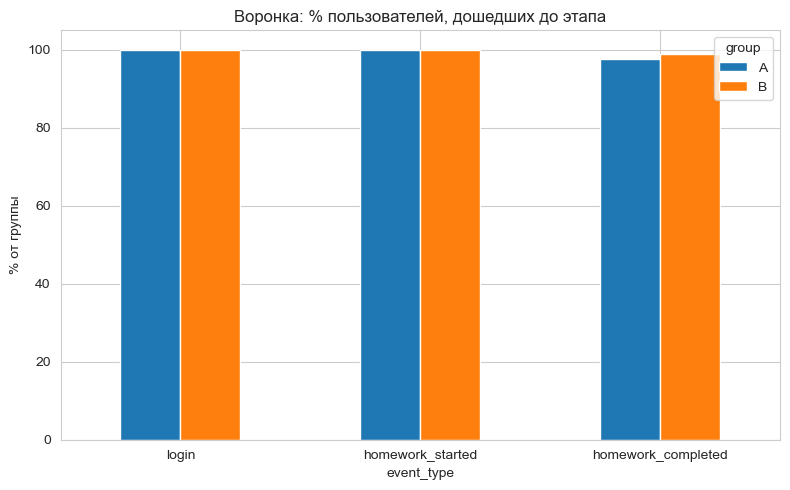

In [35]:
import matplotlib.pyplot as plt

# воронка на уровне событий (сколько уникальных user_id дошло до этапа)
funnel_steps = ['login', 'homework_started', 'homework_completed']
funnel = (events_final
          .merge(users_final[['user_id','group']], on='user_id')
          .groupby(['group','event_type'])['user_id']
          .nunique()
          .unstack()
          .reindex(columns=funnel_steps))

# нормируем на размер группы
sizes = users_final['group'].value_counts().reindex(['A','B'])
funnel_pct = (funnel.div(sizes, axis=0) * 100).round(2)

print('Воронка (уникальных user_id):')
display(funnel)
print('\nВоронка, % от группы:')
display(funnel_pct)

# график
fig, ax = plt.subplots(figsize=(8,5))
funnel_pct.T.plot(kind='bar', ax=ax)
ax.set_title('Воронка: % пользователей, дошедших до этапа')
ax.set_ylabel('% от группы')
ax.set_xticklabels(funnel_steps, rotation=0)
plt.tight_layout(); plt.show()

Средние (доли):


,completion_flag,retention_7,retention_14
group,,,
A,0.9763,0.7269,0.2881
B,0.9883,0.7798,0.3624


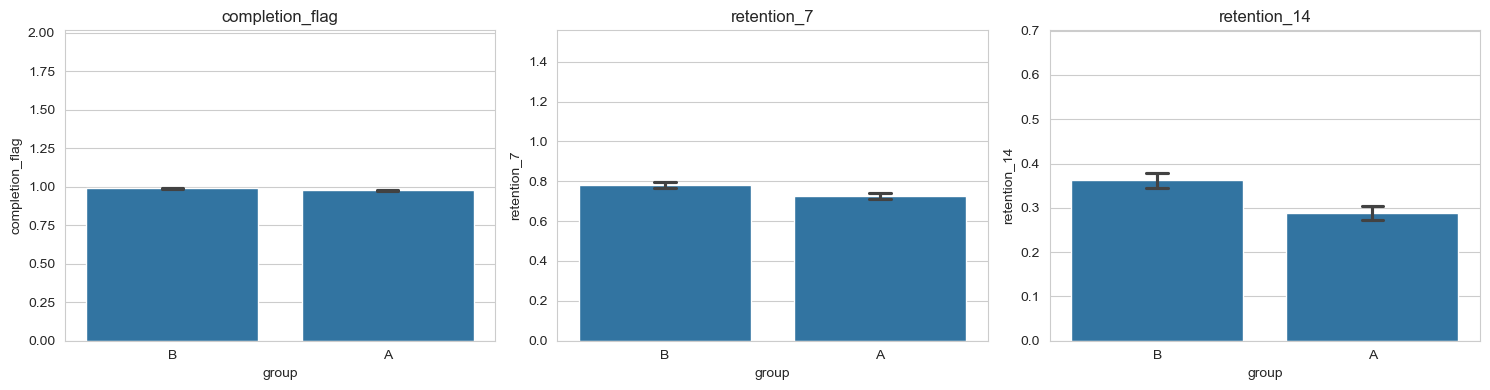

In [36]:
metrics_bin = ['completion_flag','retention_7','retention_14']

summary_bin = user_metrics.groupby('group')[metrics_bin].mean().round(4)
print('Средние (доли):')
display(summary_bin)

fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, m in zip(axes, metrics_bin):
    sns.barplot(data=user_metrics, x='group', y=m, ax=ax,
                errorbar=('ci', 95), capsize=0.1)
    ax.set_title(m)
    ax.set_ylim(0, user_metrics[m].mean()*2 + 0.05)
plt.tight_layout(); plt.show()

group                           A           B
solved_rate     count     2992.00     2987.00
                mean         0.35        0.44
                std          0.16        0.18
                min          0.00        0.00
                25%          0.25        0.31
                50%          0.33        0.44
                75%          0.44        0.57
                95%          0.62        0.73
                max          0.91        1.00
ttfc_s          count     2921.00     2953.00
                mean    319559.20   231753.99
                std     371731.02   324847.07
                min        660.00      660.00
                25%       2580.00     2220.00
                50%     181020.00    90840.00
                75%     507780.00   344520.00
                95%    1127820.00   948792.00
                max    1739160.00  1736400.00
active_days     count     2992.00     2988.00
                mean        11.96       13.13
                std          2.35 

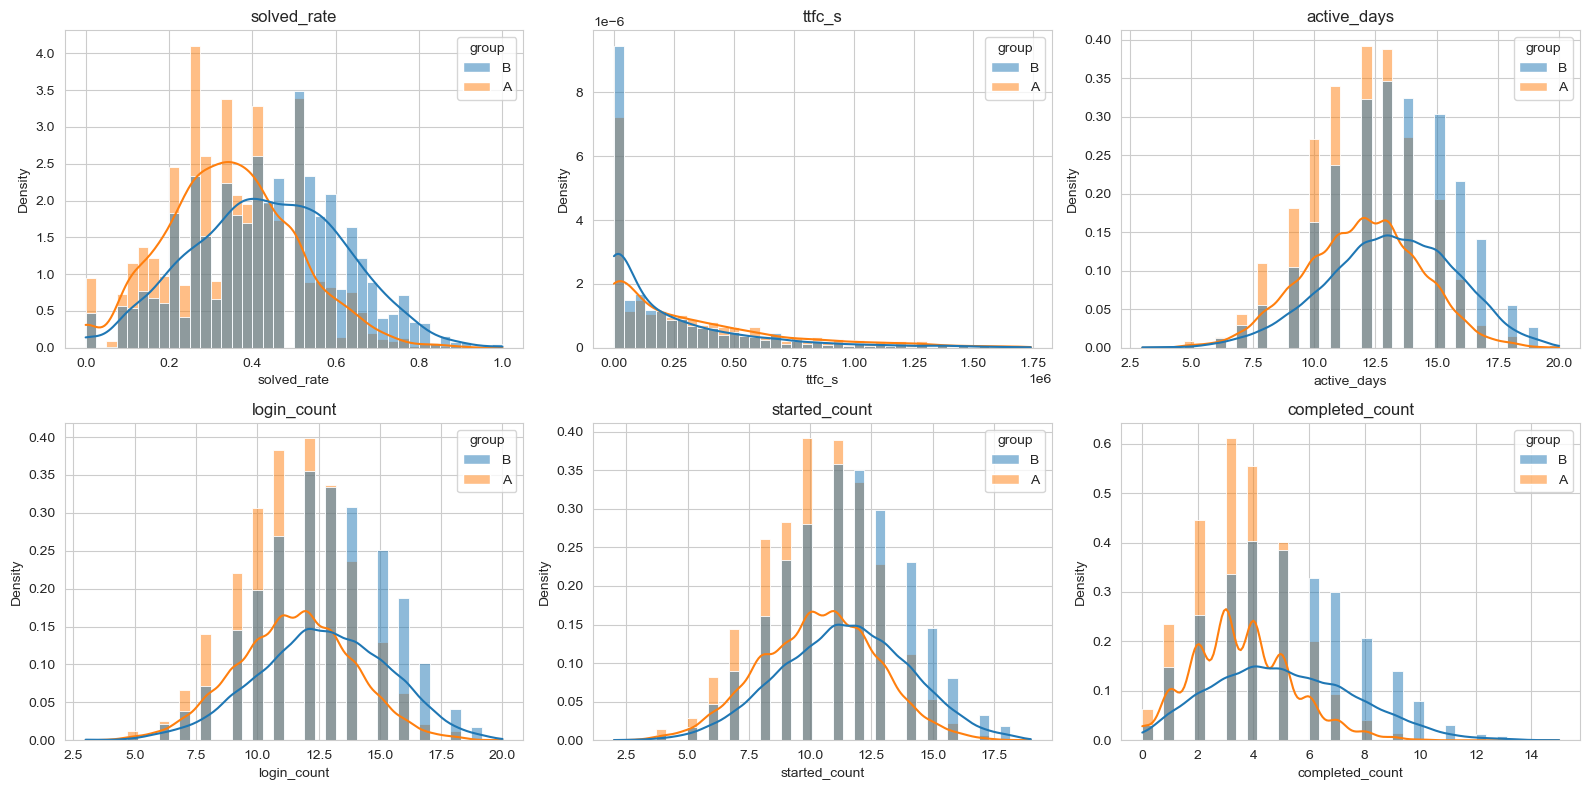

In [37]:
metrics_cont = ['solved_rate','ttfc_s','active_days','login_count',
                'started_count','completed_count']

print(user_metrics.groupby('group')[metrics_cont]
      .describe(percentiles=[.25,.5,.75,.95]).round(2).T)

fig, axes = plt.subplots(2, 3, figsize=(16,8))
axes = axes.flatten()
for ax, m in zip(axes, metrics_cont):
    sns.histplot(data=user_metrics, x=m, hue='group',
                 kde=True, stat='density', common_norm=False,
                 bins=40, ax=ax)
    ax.set_title(m)
plt.tight_layout(); plt.show()

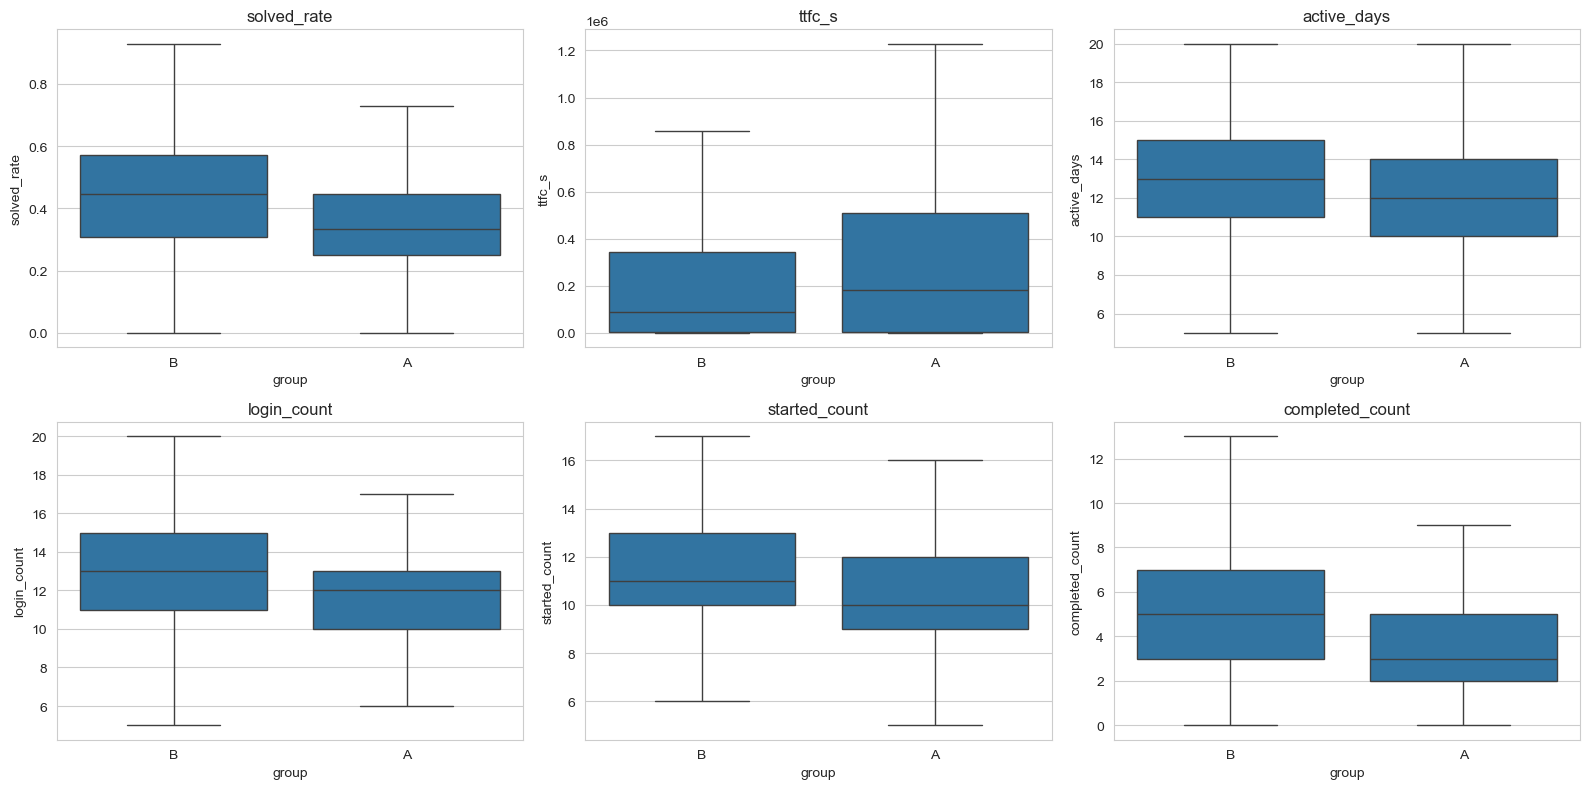

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(16,8))
axes = axes.flatten()
for ax, m in zip(axes, metrics_cont):
    sns.boxplot(data=user_metrics, x='group', y=m, ax=ax,
                showfliers=False)
    ax.set_title(m)
plt.tight_layout(); plt.show()

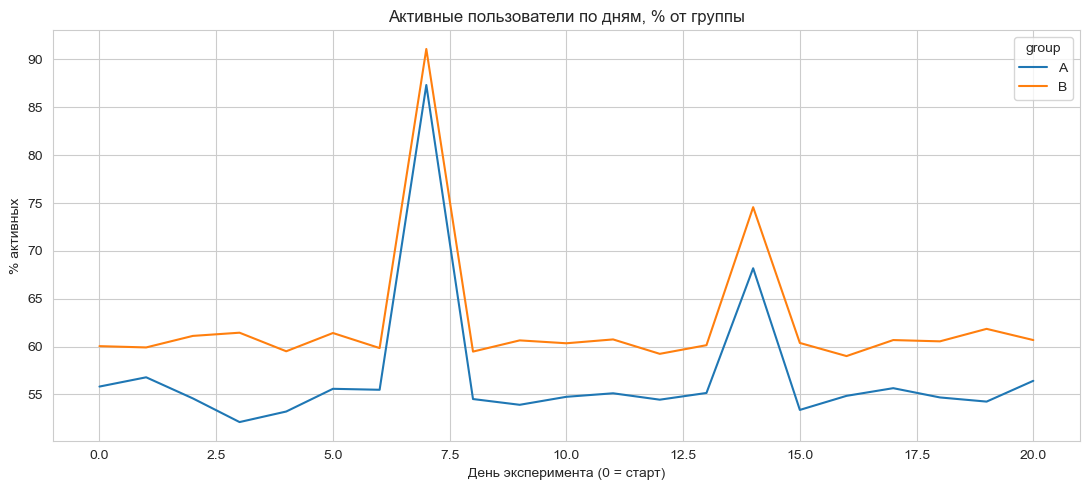

In [39]:
# кривая «доля активных пользователей в день d» от старта эксперимента
ev = events_final.merge(users_final[['user_id','group']], on='user_id')
exp_start = events_final['timestamp'].min().normalize()
ev['day'] = (ev['timestamp'].dt.normalize() - exp_start).dt.days

curves = (ev.groupby(['group','day'])['user_id'].nunique()
          .unstack(0)
          .div(sizes, axis=1) * 100)

fig, ax = plt.subplots(figsize=(11,5))
curves.plot(ax=ax)
ax.set_title('Активные пользователи по дням, % от группы')
ax.set_xlabel('День эксперимента (0 = старт)')
ax.set_ylabel('% активных')
plt.tight_layout(); plt.show()

In [40]:
from scipy.stats import shapiro, skew, kurtosis

def normality_report(series, name, n=5000):
    x = series.dropna().values
    if len(x) > n:
        x = np.random.choice(x, n, replace=False)
    stat, p = shapiro(x)
    return {
        'metric': name,
        'n': len(x),
        'skew': round(float(skew(x)), 3),
        'kurtosis': round(float(kurtosis(x)), 3),
        'shapiro_W': round(float(stat), 4),
        'shapiro_p': round(float(p), 4),
        'нормально?' : p > 0.05,
    }

report = []
for m in ['solved_rate','ttfc_s','active_days','login_count','started_count','completed_count']:
    report.append(normality_report(user_metrics[m], m))

print(pd.DataFrame(report).to_string(index=False))

         metric    n   skew  kurtosis  shapiro_W  shapiro_p  нормально?
    solved_rate 5000  0.188    -0.236     0.9938        0.0       False
         ttfc_s 5000  1.634     2.372     0.7819        0.0       False
    active_days 5000 -0.086    -0.185     0.9860        0.0       False
    login_count 5000 -0.052    -0.126     0.9867        0.0       False
  started_count 5000 -0.012    -0.146     0.9867        0.0       False
completed_count 5000  0.629     0.280     0.9583        0.0       False


In [41]:
test_choice = pd.DataFrame([
    {'metric':'completion_flag',  'type':'binary',  'test':'z-test for proportions'},
    {'metric':'retention_7',      'type':'binary',  'test':'z-test for proportions'},
    {'metric':'retention_14',     'type':'binary',  'test':'z-test for proportions'},
    {'metric':'solved_rate',      'type':'continuous, needs check', 'test':'see 5.7: t-test или Mann-Whitney'},
    {'metric':'ttfc_s',           'type':'continuous, needs check', 'test':'see 5.7'},
    {'metric':'active_days',      'type':'count, skewed',           'test':'Mann-Whitney'},
    {'metric':'login_count',      'type':'count, skewed',           'test':'Mann-Whitney'},
    {'metric':'started_count',    'type':'count, skewed',           'test':'Mann-Whitney'},
    {'metric':'completed_count',  'type':'count, skewed',           'test':'Mann-Whitney'},
])
display(test_choice)

,metric,type,test
0,completion_flag,binary,z-test for proportions
1,retention_7,binary,z-test for proportions
2,retention_14,binary,z-test for proportions
3,solved_rate,"continuous, needs check",see 5.7: t-test или Mann-Whitney
4,ttfc_s,"continuous, needs check",see 5.7
5,active_days,"count, skewed",Mann-Whitney
6,login_count,"count, skewed",Mann-Whitney
7,started_count,"count, skewed",Mann-Whitney
8,completed_count,"count, skewed",Mann-Whitney


# Блок 5. Разведочный анализ — итог

## 5.1. Воронка (уникальных user_id, % от группы)

| Этап | A | B |
|---|---|---|
| login | 100.0 % | 100.0 % |
| homework_started | 100.0 % | 100.0 % |
| homework_completed | **97.63 %** | **98.83 %** |

Абсолют: A = 2992 → 2992 → 2921, B = 2988 → 2988 → 2953.
Разрыв возникает только на последнем шаге — это и есть основной сигнал по completion.

## 5.2. Бинарные метрики

| Метрика | A | B | Разница, п.п. |
|---|---|---|---|
| completion_flag | 0.9763 | 0.9883 | +1.20 |
| retention_7 | 0.7269 | 0.7798 | +5.29 |
| retention_14 | 0.2881 | 0.3624 | +7.43 |

## 5.3. Непрерывные метрики

| Метрика | A (mean) | B (mean) | A (median) | B (median) | A (95%) | B (95%) |
|---|---|---|---|---|---|---|
| solved_rate | 0.35 | 0.44 | 0.33 | 0.44 | 0.62 | 0.73 |
| ttfc_s, сек | 319 559 | 231 754 | 181 020 | 90 840 | 1 127 820 | 948 792 |
| active_days | 11.96 | 13.13 | 12 | 13 | 16 | 17 |
| login_count | 11.51 | 12.67 | 12 | 13 | 15 | 17 |
| started_count | 10.36 | 11.42 | 10 | 11 | 14 | 16 |
| completed_count | 3.58 | 5.11 | 3 | 5 | 7 | 10 |

Все непрерывные метрики смещены в пользу B.

## 5.4. Нормальность (Shapiro, n=5000)

| Метрика | skew | kurtosis | W | p | Нормально? |
|---|---|---|---|---|---|
| solved_rate | 0.188 | −0.236 | 0.9938 | ~0 | нет (mild) |
| ttfc_s | 1.634 | 2.372 | 0.7819 | ~0 | нет (strong right skew) |
| active_days | −0.086 | −0.185 | 0.9860 | ~0 | нет (mild) |
| login_count | −0.052 | −0.126 | 0.9867 | ~0 | нет (mild) |
| started_count | −0.012 | −0.146 | 0.9867 | ~0 | нет (mild) |
| completed_count | 0.629 | 0.280 | 0.9583 | ~0 | нет (mild) |

**Важно:** Shapiro при n=5000 переоткрывает нормальность почти для любого отклонения. Опираемся не только на p, но и на форму:
- `ttfc_s` — сильно скошена (skew 1.63) → **Mann-Whitney**.
- `solved_rate`, `active_days`, `*_count` — mild skew, при n≈3000 **CLT** делает t-test на средних допустимым.

## 5.5. Выбор критериев (финальный)

| Метрика | Тип | Основной тест | Робастность |
|---|---|---|---|
| completion_flag | binary | z-test for proportions | χ², Bootstrap CI |
| retention_7 | binary | z-test for proportions | χ², Bootstrap CI |
| retention_14 | binary | z-test for proportions | χ², Bootstrap CI |
| solved_rate | continuous, mild skew | t-test (Welch) | Mann-Whitney |
| ttfc_s | continuous, strong skew | **Mann-Whitney** | t-test по log, Bootstrap по медиане |
| active_days | count | **Mann-Whitney** | t-test по log, Bootstrap |
| login_count | count | **Mann-Whitney** | t-test по log |
| started_count | count | **Mann-Whitney** | t-test по log |
| completed_count | count | **Mann-Whitney** | t-test по log |

## 5.6. Наблюдения перед тестами

1. **Все метрики в пользу B** — консистентный сигнал.
2. **Эффекты выглядят большими** для одной фичи (retention_14 +7.4 п.п., ttfc ×2, completed_count +43%). Это риск: либо реальный сильный эффект, либо загрязнение / разная методика проставления событий. Проверка — в Блоке 8 (сегменты, устойчивость, выбросы).
3. **completion_flag близок к потолку** (97.6 / 98.8 %). Практическая значимость ограничена, но z-test при n≈3000 даст значимость.
4. **NaN в ttfc_s** — 106 (1.8 %), исключаем из теста по скорости. NaN в solved_rate — 1 (0.0 %).
5. **Ключевая метрика — retention_14**: там эффект +7.4 п.п. и меньше потолка. Именно она будет решающей для бизнес-вывода.

## 5.7. Что дальше

Переходим к Блоку 6 — фиксируем критерии и обосновываем выбор. Затем Блок 7 — расчёт:
- z-test + CI для 3 бинарных метрик;
- Welch t-test + Mann-Whitney + Bootstrap CI для solved_rate;
- Mann-Whitney + Bootstrap CI для ttfc_s;
- Mann-Whitney для count-метрик;
- эффект-сайзы (Cohen's h, r, разница медиан);
- MDE и post-hoc power;
- коррекция множественных сравнений (Holm–Bonferroni).

# Блок 6. Критерии решения и статистические гипотезы

**Цель:** до расчёта зафиксировать:
- какие гипотезы проверяем (H0/H1);
- какой тест соответствует каждой метрике;
- какой уровень значимости и мощность;
- как учитываем множественные сравнения;
- какое значение эффекта считаем practically significant;
- какой MDE достижим на текущей выборке.

Все определения взяты из Блока 0 и уточнены по итогам Блока 5.

## 6.1. Общие параметры

| Параметр | Значение | Источник |
|---|---|---|
| Уровень значимости α | 0.05 | Блок 0 |
| Мощность 1 − β | 0.80 | Блок 0 |
| Тип теста | двусторонний | Блок 0 |
| Размеры групп | A = 2992, B = 2988 | Блок 3 |
| Множественные сравнения | Holm–Bonferroni | Блок 0 |
| Семейство тестов | 9 метрик (3 бинарных + 6 непрерывных/каунт) | уточнено |
| Минимальный practically significant effect | +2 п.п. для completion; +3 п.п. для retention_7/14; +0.05 для solved_rate; −1 день для ttfc | Блок 0 |

## 6.2. Правила вывода для каждой метрики

Для каждой метрики фиксируется:
1. Направление эффекта: односторонний интерес в пользу B, но тест двусторонний.
2. Условие «значимо»: p_adj < α.
3. Условие «практически значимо»: точечная оценка эффекта ≥ practically significant effect.
4. Условие «не хуже»: нижняя граница 95 % CI для разницы ≥ 0 (для метрик, где важен риск падения).

## 6.3. Гипотезы H0 / H1 по метрикам

### Бинарные (z-test for proportions)

**completion_flag**
- H0: p_B − p_A = 0 (геймификация не меняет completion rate).
- H1: p_B − p_A ≠ 0.
- practically significant: ≥ +2 п.п.
- Тест: two-proportion z-test, двусторонний.
- Робастность: χ², Bootstrap 10 000 повторов.

**retention_7**
- H0: p_B − p_A = 0.
- H1: p_B − p_A ≠ 0.
- practically significant: ≥ +3 п.п.
- Тест: two-proportion z-test.
- Робастность: χ², Bootstrap.

**retention_14**
- H0: p_B − p_A = 0.
- H1: p_B − p_A ≠ 0.
- practically significant: ≥ +3 п.п.
- Тест: two-proportion z-test.
- Робастность: χ², Bootstrap.

### Непрерывные / count

**solved_rate**
- H0: распределение в A = распределению в B (или mean_A = mean_B).
- H1: различия есть.
- Основной тест: Welch t-test (mild skew, n ≈ 3000, CLT применим к средним).
- Робастность: Mann-Whitney U, Bootstrap по разнице средних.
- practically significant: |Δ mean| ≥ 0.05.

**ttfc_s**
- H0: распределение одинаково.
- H1: различается.
- Основной тест: **Mann-Whitney U** (strong right skew, skew = 1.63).
- Робастность: t-test по log(ttfc), Bootstrap по разнице медиан.
- practically significant: медиана падает ≥ чем на 1 день (86 400 сек).

**active_days, login_count, started_count, completed_count**
- H0: распределения одинаковы.
- H1: различаются.
- Основной тест: **Mann-Whitney U** (count-метрики, скошены).
- Робастность: t-test по log, Bootstrap.
- practically significant: +1 день для active_days; для *_count — качественная оценка через effect size (r).

## 6.4. Множественные сравнения

Мы проверяем 9 метрик. Без коррекции вероятность хотя бы одного ложноположительного результата:

FWER ≈ 1 − (1 − 0.05)^9 ≈ 0.37.

**Применяем Holm–Bonferroni** к семейству из 9 p-value:
- сортируем p возрастанию;
- порог для i-й гипотезы: α / (m − i + 1);
- как только гипотеза не проходит — все следующие отклоняются.

Семейство: 9 тестов (3 z-test + 1 Welch + 1 MW (ttfc) + 4 MW (count)).

MDE и post-hoc power считаем без коррекции — они информационные, не решающие.

## 6.5. Чувствительность и условия пересмотра

Рекомендация пересматривается, если выполнено хотя бы одно:

1. После Holm–Bonferroni значимость по retention_7 или retention_14 пропадает.
2. 95 % CI для retention_14 включает 0.
3. Сегментированный анализ (Блок 8) показывает, что эффект сосредоточен в одном grade и отсутствует в остальных.
4. Проверка устойчивости к выбросам (Блок 8) сдвигает точечную оценку эффекта более чем на 20 %.
5. Разные определения retention (exact day vs окно) дают противоположные выводы.
6. Эффект в B по ключевой метрике < practically significant (2–3 п.п.).
7. Появляется сигнал падения другой ключевой метрики (например, retention_14 растёт, а completion_flag падает).

## 6.6. MDE (минимальный обнаруживаемый эффект)

Оценка при α = 0.05, power = 0.80, двусторонний тест, n_A ≈ n_B ≈ 3000.

Для долей (NormalIndPower):

MDE ≈ (z_{1−α/2} + z_{1−β}) · √( p_A(1−p_A) / n_A + p_B(1−p_B) / n_B ).

Ориентировочно:
- p ≈ 0.10 → MDE ≈ 1.0 п.п.
- p ≈ 0.30 → MDE ≈ 1.5 п.п.
- p ≈ 0.50 → MDE ≈ 1.6 п.п.
- p ≈ 0.75 → MDE ≈ 1.5 п.п.
- p ≈ 0.95 → MDE ≈ 0.7 п.п.

Точные значения посчитаем в Блоке 7.

## 6.7. Ожидаемая устойчивость

По итогам Блока 5:
- Все метрики смещены в B консистентно → низкая вероятность случайного паттерна.
- Эффекты крупные → вероятность статистической значимости высокая даже после коррекции.
- Главный риск — **не статистика, а валидность эффекта** (загрязнение, методика retention, потолок по completion). Это адресуем в Блоке 8.

# Блок 7. Статистический расчёт

**Цель:** для каждой метрики получить:
- точечную оценку разницы A vs B;
- 95 % доверительный интервал;
- p-value (двусторонний);
- effect size;
- p-value с коррекцией Holm–Bonferroni;
- сопоставление с practically significant effect из Блока 6;
- MDE и post-hoc power.

**Правила из Блока 6:**
- binary → z-test + Bootstrap + χ²;
- solved_rate → Welch t-test + MW + Bootstrap;
- ttfc_s → MW + Bootstrap по медиане;
- count-метрики → MW + effect size r;
- Holm–Bonferroni по 9 тестам.

In [50]:
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests
from scipy import stats
from scipy.optimize import brentq
import numpy as np
import pandas as pd
from IPython.display import display

RNG = np.random.default_rng(42)
N_BOOT = 10_000

A = user_metrics[user_metrics['group'] == 'A']
B = user_metrics[user_metrics['group'] == 'B']

n_A, n_B = len(A), len(B)
print('n_A =', n_A, '| n_B =', n_B)

results = []

n_A = 2992 | n_B = 2988


In [51]:
def z_test_proportions(A_vals, B_vals, metric):
    n_a, n_b = len(A_vals), len(B_vals)
    x_a, x_b = int(A_vals.sum()), int(B_vals.sum())
    p_a, p_b = x_a / n_a, x_b / n_b

    stat, p_val = proportions_ztest([x_b, x_a], [n_b, n_a], alternative='two-sided')

    ci_a = proportion_confint(x_a, n_a, alpha=0.05, method='wilson')
    ci_b = proportion_confint(x_b, n_b, alpha=0.05, method='wilson')

    se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    diff = p_b - p_a
    ci_diff = (diff - 1.96 * se, diff + 1.96 * se)

    h = 2 * np.arcsin(np.sqrt(p_b)) - 2 * np.arcsin(np.sqrt(p_a))

    return {
        'metric': metric, 'kind': 'binary', 'test': 'z-test',
        'n_A': n_a, 'n_B': n_b,
        'A': p_a, 'B': p_b, 'diff': diff,
        'ci_low': ci_diff[0], 'ci_high': ci_diff[1],
        'stat': stat, 'p_value': p_val,
        'effect_size_name': "Cohen's h", 'effect_size': h,
        'A_ci_low': ci_a[0], 'A_ci_high': ci_a[1],
        'B_ci_low': ci_b[0], 'B_ci_high': ci_b[1],
    }


def bootstrap_diff_prop(A_vals, B_vals, n_boot=N_BOOT, seed=42):
    rng = np.random.default_rng(seed)
    a = A_vals.values
    b = B_vals.values
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        sa = rng.choice(a, size=len(a), replace=True)
        sb = rng.choice(b, size=len(b), replace=True)
        diffs[i] = sb.mean() - sa.mean()
    return np.percentile(diffs, [2.5, 97.5])

In [52]:
binary_metrics = ['completion_flag', 'retention_7', 'retention_14']

for m in binary_metrics:
    row = z_test_proportions(A[m], B[m], m)

    ci_boot = bootstrap_diff_prop(A[m], B[m])
    row['boot_ci_low'], row['boot_ci_high'] = ci_boot

    tab = pd.crosstab(user_metrics['group'], user_metrics[m])
    chi2, p_chi2, _, _ = stats.chi2_contingency(tab, correction=False)
    row['chi2'] = chi2
    row['p_chi2'] = p_chi2

    results.append(row)

display(pd.DataFrame(results))

,metric,kind,test,n_A,n_B,A,B,diff,ci_low,ci_high,stat,p_value,effect_size_name,effect_size,A_ci_low,A_ci_high,B_ci_low,B_ci_high,boot_ci_low,boot_ci_high,chi2,p_chi2
0,completion_flag,binary,z-test,2992,2988,0.976270,0.988286,0.012016,0.005336,0.018697,3.521090,4.297772e-04,Cohen's h,0.092439,0.970175,0.981144,0.983754,0.991566,0.005661,0.018704,12.398073,4.297772e-04
1,retention_7,binary,z-test,2992,2988,0.726939,0.779786,0.052847,0.031038,0.074656,4.740249,2.134559e-06,Cohen's h,0.122757,0.710691,0.742604,0.764574,0.794280,0.031117,0.074587,22.469959,2.134559e-06
2,retention_14,binary,z-test,2992,2988,0.288102,0.362450,0.074348,0.050675,0.098022,6.136356,8.443589e-10,Cohen's h,0.158939,0.272154,0.304593,0.345400,0.379852,0.050944,0.098105,37.654864,8.443589e-10


In [53]:
def welch_t_test(A_vals, B_vals, metric):
    a = A_vals.dropna().values
    b = B_vals.dropna().values
    stat, p = stats.ttest_ind(b, a, equal_var=False, alternative='two-sided')

    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))
    df_num = (a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))**2
    df_den = (a.var(ddof=1)/len(a))**2/(len(a)-1) + (b.var(ddof=1)/len(b))**2/(len(b)-1)
    df = df_num / df_den
    t_crit = stats.t.ppf(0.975, df)
    ci = (diff - t_crit * se, diff + t_crit * se)

    pooled_sd = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2))
    d = diff / pooled_sd if pooled_sd > 0 else np.nan

    return {
        'metric': metric, 'kind': 'continuous', 'test': 'Welch t-test',
        'n_A': len(a), 'n_B': len(b),
        'A': a.mean(), 'B': b.mean(), 'diff': diff,
        'ci_low': ci[0], 'ci_high': ci[1],
        'stat': stat, 'p_value': p, 'df': df,
        'effect_size_name': "Cohen's d", 'effect_size': d,
    }


def mannwhitney(A_vals, B_vals, metric):
    a = A_vals.dropna().values
    b = B_vals.dropna().values
    stat, p = stats.mannwhitneyu(b, a, alternative='two-sided')

    med_a, med_b = np.median(a), np.median(b)
    diff_med = med_b - med_a

    n = len(a) + len(b)
    mean_u = len(a) * len(b) / 2
    sd_u = np.sqrt(len(a) * len(b) * (n + 1) / 12)
    z = (stat - mean_u) / sd_u
    r = z / np.sqrt(n)

    return {
        'metric': metric, 'kind': 'continuous', 'test': 'Mann-Whitney U',
        'n_A': len(a), 'n_B': len(b),
        'A': med_a, 'B': med_b, 'diff': diff_med,
        'ci_low': np.nan, 'ci_high': np.nan,
        'stat': stat, 'p_value': p, 'z': z,
        'effect_size_name': 'r', 'effect_size': r,
    }


def bootstrap_diff_mean(A_vals, B_vals, n_boot=N_BOOT, seed=42):
    rng = np.random.default_rng(seed)
    a = A_vals.dropna().values
    b = B_vals.dropna().values
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        sa = rng.choice(a, size=len(a), replace=True)
        sb = rng.choice(b, size=len(b), replace=True)
        diffs[i] = sb.mean() - sa.mean()
    return np.percentile(diffs, [2.5, 97.5])


def bootstrap_diff_median(A_vals, B_vals, n_boot=N_BOOT, seed=42):
    rng = np.random.default_rng(seed)
    a = A_vals.dropna().values
    b = B_vals.dropna().values
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        sa = rng.choice(a, size=len(a), replace=True)
        sb = rng.choice(b, size=len(b), replace=True)
        diffs[i] = np.median(sb) - np.median(sa)
    return np.percentile(diffs, [2.5, 97.5])

In [54]:
m = 'solved_rate'
row = welch_t_test(A[m], B[m], m)
row['boot_ci_low'], row['boot_ci_high'] = bootstrap_diff_mean(A[m], B[m])
row_mw = mannwhitney(A[m], B[m], m)
row['mw_stat']  = row_mw['stat']
row['mw_p']     = row_mw['p_value']
row['mw_r']     = row_mw['effect_size']
results.append(row)

display(pd.DataFrame([row]))

,metric,kind,test,n_A,n_B,A,B,diff,ci_low,ci_high,stat,p_value,df,effect_size_name,effect_size,boot_ci_low,boot_ci_high,mw_stat,mw_p,mw_r
0,solved_rate,continuous,Welch t-test,2992,2987,0.346066,0.437946,0.091881,0.083313,0.100448,21.022902,1.193356e-94,5847.890008,Cohen's d,0.543828,0.083365,0.100476,5807789.5,1.049917e-89,0.259528


In [55]:
m = 'ttfc_s'
row = mannwhitney(A[m], B[m], m)
row['boot_ci_low'], row['boot_ci_high'] = bootstrap_diff_median(A[m], B[m])
results.append(row)

display(pd.DataFrame([row]))

,metric,kind,test,n_A,n_B,A,B,diff,ci_low,ci_high,stat,p_value,z,effect_size_name,effect_size,boot_ci_low,boot_ci_high
0,ttfc_s,continuous,Mann-Whitney U,2921,2953,181020.0,90840.0,-90180.0,NaN,NaN,3664384.5,1.883120e-23,-9.978848,r,-0.130201,-97920.0,-84000.0


In [56]:
for m in ['active_days', 'login_count', 'started_count', 'completed_count']:
    row = mannwhitney(A[m], B[m], m)
    row['boot_ci_low'], row['boot_ci_high'] = bootstrap_diff_median(A[m], B[m])
    results.append(row)

display(pd.DataFrame(results[-4:]))

,metric,kind,test,n_A,n_B,A,B,diff,ci_low,ci_high,stat,p_value,z,effect_size_name,effect_size,boot_ci_low,boot_ci_high
0,active_days,continuous,Mann-Whitney U,2992,2988,12.0,13.0,1.0,NaN,NaN,5644258.0,3.325827e-70,17.590509,r,0.227472,1.0,1.0
1,login_count,continuous,Mann-Whitney U,2992,2988,12.0,13.0,1.0,NaN,NaN,5625179.0,5.359588e-68,17.304692,r,0.223776,1.0,2.0
2,started_count,continuous,Mann-Whitney U,2992,2988,10.0,11.0,1.0,NaN,NaN,5509247.5,2.122565e-55,15.567955,r,0.201317,0.0,2.0
3,completed_count,continuous,Mann-Whitney U,2992,2988,3.0,5.0,2.0,NaN,NaN,6056302.0,3.608116e-127,23.763224,r,0.307294,1.0,2.0


In [57]:
res = pd.DataFrame(results)

order = ['completion_flag','retention_7','retention_14',
         'solved_rate','ttfc_s',
         'active_days','login_count','started_count','completed_count']
res['metric'] = pd.Categorical(res['metric'], categories=order, ordered=True)
res = res.sort_values('metric').reset_index(drop=True)

cols_show = ['metric','kind','test','n_A','n_B','A','B','diff',
             'ci_low','ci_high','p_value','effect_size_name','effect_size']
display(res[cols_show])

,metric,kind,test,n_A,n_B,A,B,diff,ci_low,ci_high,p_value,effect_size_name,effect_size
0,completion_flag,binary,z-test,2992,2988,0.976270,0.988286,0.012016,0.005336,0.018697,4.297772e-04,Cohen's h,0.092439
1,retention_7,binary,z-test,2992,2988,0.726939,0.779786,0.052847,0.031038,0.074656,2.134559e-06,Cohen's h,0.122757
2,retention_14,binary,z-test,2992,2988,0.288102,0.362450,0.074348,0.050675,0.098022,8.443589e-10,Cohen's h,0.158939
3,solved_rate,continuous,Welch t-test,2992,2987,0.346066,0.437946,0.091881,0.083313,0.100448,1.193356e-94,Cohen's d,0.543828
4,ttfc_s,continuous,Mann-Whitney U,2921,2953,181020.000000,90840.000000,-90180.000000,NaN,NaN,1.883120e-23,r,-0.130201
5,active_days,continuous,Mann-Whitney U,2992,2988,12.000000,13.000000,1.000000,NaN,NaN,3.325827e-70,r,0.227472
6,login_count,continuous,Mann-Whitney U,2992,2988,12.000000,13.000000,1.000000,NaN,NaN,5.359588e-68,r,0.223776
7,started_count,continuous,Mann-Whitney U,2992,2988,10.000000,11.000000,1.000000,NaN,NaN,2.122565e-55,r,0.201317
8,completed_count,continuous,Mann-Whitney U,2992,2988,3.000000,5.000000,2.000000,NaN,NaN,3.608116e-127,r,0.307294


In [58]:
p_vals = res['p_value'].values
rej, p_adj, _, _ = multipletests(p_vals, alpha=ALPHA, method='holm')

res['p_adj_holm']       = p_adj
res['significant_raw']  = res['p_value'] < ALPHA
res['significant_holm'] = rej

display(res[['metric','p_value','p_adj_holm',
             'significant_raw','significant_holm']])

,metric,p_value,p_adj_holm,significant_raw,significant_holm
0,completion_flag,4.297772e-04,4.297772e-04,True,True
1,retention_7,2.134559e-06,4.269118e-06,True,True
2,retention_14,8.443589e-10,2.533077e-09,True,True
3,solved_rate,1.193356e-94,9.546849e-94,True,True
4,ttfc_s,1.883120e-23,7.532479e-23,True,True
5,active_days,3.325827e-70,2.328079e-69,True,True
6,login_count,5.359588e-68,3.215753e-67,True,True
7,started_count,2.122565e-55,1.061283e-54,True,True
8,completed_count,3.608116e-127,3.247305e-126,True,True


In [59]:
PS = {
    'completion_flag': 0.02,
    'retention_7': 0.03,
    'retention_14': 0.03,
    'solved_rate': 0.05,
    'ttfc_s': 86400,
    'active_days': 1,
    'login_count': None,
    'started_count': None,
    'completed_count': None,
}

res['pract_sig_threshold'] = res['metric'].astype(str).map(PS)
res['pract_sig_met'] = res.apply(
    lambda r: (abs(r['diff']) >= r['pract_sig_threshold'])
              if pd.notna(r['pract_sig_threshold']) else None,
    axis=1
)

display(res[['metric','diff','ci_low','ci_high',
             'pract_sig_threshold','pract_sig_met',
             'significant_holm']])

,metric,diff,ci_low,ci_high,pract_sig_threshold,pract_sig_met,significant_holm
0,completion_flag,0.012016,0.005336,0.018697,0.02,False,True
1,retention_7,0.052847,0.031038,0.074656,0.03,True,True
2,retention_14,0.074348,0.050675,0.098022,0.03,True,True
3,solved_rate,0.091881,0.083313,0.100448,0.05,True,True
4,ttfc_s,-90180.000000,NaN,NaN,86400.00,True,True
5,active_days,1.000000,NaN,NaN,1.00,True,True
6,login_count,1.000000,NaN,NaN,NaN,None,True
7,started_count,1.000000,NaN,NaN,NaN,None,True
8,completed_count,2.000000,NaN,NaN,NaN,None,True


In [60]:
analysis = NormalIndPower()
mde_table = []

def h_diff(p1, p2):
    return 2*np.arcsin(np.sqrt(p2)) - 2*np.arcsin(np.sqrt(p1))

def min_abs_h(n, alpha=ALPHA, power=POWER):
    z_a = stats.norm.ppf(1 - alpha/2)
    z_b = stats.norm.ppf(power)
    return (z_a + z_b) * np.sqrt(2 / n)

for m in ['completion_flag','retention_7','retention_14']:
    p_A = A[m].mean()
    n_per_group = min(n_A, n_B)
    h_min = min_abs_h(n_per_group)

    try:
        p2_up = brentq(lambda p2: h_diff(p_A, p2) - h_min, p_A + 1e-6, 1 - 1e-9)
    except ValueError:
        p2_up = np.nan
    try:
        p2_dn = brentq(lambda p2: h_min - h_diff(p_A, p2), 1e-6, p_A - 1e-6)
    except ValueError:
        p2_dn = np.nan

    mde_up = p2_up - p_A if pd.notna(p2_up) else np.nan
    mde_dn = p_A - p2_dn if pd.notna(p2_dn) else np.nan

    mde_table.append({
        'metric': m, 'p_A': p_A, 'n_per_group': n_per_group,
        'MDE_up_pp': mde_up*100, 'MDE_down_pp': mde_dn*100,
    })

mde_df = pd.DataFrame(mde_table)
display(mde_df)

,metric,p_A,n_per_group,MDE_up_pp,MDE_down_pp
0,completion_flag,0.976270,2988,0.977202,NaN
1,retention_7,0.726939,2988,3.166881,NaN
2,retention_14,0.288102,2988,3.335306,NaN


In [61]:
z_a = stats.norm.ppf(1 - ALPHA/2)
z_b = stats.norm.ppf(POWER)

mde_cont = []
for m in ['solved_rate','ttfc_s','active_days',
          'login_count','started_count','completed_count']:
    a = A[m].dropna().values
    b = B[m].dropna().values
    sd_pooled = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1))
                        / (len(a)+len(b)-2))
    n_per_group = min(len(a), len(b))
    d_min = (z_a + z_b) * np.sqrt(2 / n_per_group)
    mde_abs = d_min * sd_pooled
    mde_cont.append({
        'metric': m, 'sd_pooled': sd_pooled,
        'd_min': d_min, 'MDE_abs': mde_abs,
    })

display(pd.DataFrame(mde_cont))

,metric,sd_pooled,d_min,MDE_abs
0,solved_rate,0.168951,0.072494,0.012248
1,ttfc_s,348949.564236,0.073308,25580.893932
2,active_days,2.490867,0.072482,0.180542
3,login_count,2.508496,0.072482,0.181820
4,started_count,2.489639,0.072482,0.180453
5,completed_count,2.188954,0.072482,0.158659


In [62]:
power_rows = []

for _, r in res.iterrows():
    metric_name = str(r['metric'])
    a = A[metric_name].dropna().values
    b = B[metric_name].dropna().values
    n_per_group = min(len(a), len(b))

    if r['kind'] == 'binary':
        p_a = a.mean(); p_b = b.mean()
        h_obs = abs(2*np.arcsin(np.sqrt(p_b)) - 2*np.arcsin(np.sqrt(p_a)))
        try:
            pwr = analysis.power(effect_size=h_obs, nobs1=n_per_group,
                                 alpha=ALPHA, ratio=1.0, alternative='two-sided')
        except Exception:
            pwr = np.nan
    else:
        sd_pooled = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1))
                            / (len(a)+len(b)-2))
        d_obs = (b.mean() - a.mean()) / sd_pooled if sd_pooled > 0 else np.nan
        try:
            pwr = analysis.power(effect_size=abs(d_obs), nobs1=n_per_group,
                                 alpha=ALPHA, ratio=1.0, alternative='two-sided')
        except Exception:
            pwr = np.nan

    power_rows.append({'metric': metric_name, 'power_posthoc': pwr})

res = res.merge(pd.DataFrame(power_rows), on='metric', how='left')
display(res[['metric','p_value','significant_holm','power_posthoc']])

,metric,p_value,significant_holm,power_posthoc
0,completion_flag,4.297772e-04,True,0.946631
1,retention_7,2.134559e-06,True,0.997323
2,retention_14,8.443589e-10,True,0.999986
3,solved_rate,1.193356e-94,True,1.000000
4,ttfc_s,1.883120e-23,True,1.000000
5,active_days,3.325827e-70,True,1.000000
6,login_count,5.359588e-68,True,1.000000
7,started_count,2.122565e-55,True,1.000000
8,completed_count,3.608116e-127,True,1.000000


In [63]:
res.to_csv('ab_test_results.csv', index=False)
print('saved ab_test_results.csv')
print('columns:', list(res.columns))

saved ab_test_results.csv
columns: ['metric', 'kind', 'test', 'n_A', 'n_B', 'A', 'B', 'diff', 'ci_low', 'ci_high', 'stat', 'p_value', 'effect_size_name', 'effect_size', 'A_ci_low', 'A_ci_high', 'B_ci_low', 'B_ci_high', 'boot_ci_low', 'boot_ci_high', 'chi2', 'p_chi2', 'df', 'mw_stat', 'mw_p', 'mw_r', 'z', 'p_adj_holm', 'significant_raw', 'significant_holm', 'pract_sig_threshold', 'pract_sig_met', 'power_posthoc']


In [64]:
final = res[[
    'metric','A','B','diff','ci_low','ci_high',
    'p_value','p_adj_holm','significant_holm',
    'effect_size_name','effect_size',
    'pract_sig_threshold','pract_sig_met','power_posthoc'
]].copy()

if 'boot_ci_low' in res.columns:
    final['boot_ci_low']  = res['boot_ci_low']
    final['boot_ci_high'] = res['boot_ci_high']

display(final)

,metric,A,B,diff,ci_low,ci_high,p_value,p_adj_holm,significant_holm,effect_size_name,effect_size,pract_sig_threshold,pract_sig_met,power_posthoc,boot_ci_low,boot_ci_high
0,completion_flag,0.976270,0.988286,0.012016,0.005336,0.018697,4.297772e-04,4.297772e-04,True,Cohen's h,0.092439,0.02,False,0.946631,0.005661,0.018704
1,retention_7,0.726939,0.779786,0.052847,0.031038,0.074656,2.134559e-06,4.269118e-06,True,Cohen's h,0.122757,0.03,True,0.997323,0.031117,0.074587
2,retention_14,0.288102,0.362450,0.074348,0.050675,0.098022,8.443589e-10,2.533077e-09,True,Cohen's h,0.158939,0.03,True,0.999986,0.050944,0.098105
3,solved_rate,0.346066,0.437946,0.091881,0.083313,0.100448,1.193356e-94,9.546849e-94,True,Cohen's d,0.543828,0.05,True,1.000000,0.083365,0.100476
4,ttfc_s,181020.000000,90840.000000,-90180.000000,NaN,NaN,1.883120e-23,7.532479e-23,True,r,-0.130201,86400.00,True,1.000000,-97920.000000,-84000.000000
5,active_days,12.000000,13.000000,1.000000,NaN,NaN,3.325827e-70,2.328079e-69,True,r,0.227472,1.00,True,1.000000,1.000000,1.000000
6,login_count,12.000000,13.000000,1.000000,NaN,NaN,5.359588e-68,3.215753e-67,True,r,0.223776,NaN,None,1.000000,1.000000,2.000000
7,started_count,10.000000,11.000000,1.000000,NaN,NaN,2.122565e-55,1.061283e-54,True,r,0.201317,NaN,None,1.000000,0.000000,2.000000
8,completed_count,3.000000,5.000000,2.000000,NaN,NaN,3.608116e-127,3.247305e-126,True,r,0.307294,NaN,None,1.000000,1.000000,2.000000


# Блок 7. Результаты

## 7.1. Бинарные метрики (z-test, n_A=2992, n_B=2988)

| Метрика | A | B | Δ, п.п. | 95% CI (Δ) | p (z) | p_holm | prac.sig (≥) | Значимо | Cohen's h |
|---|---|---|---|---|---|---|---|---|---|
| completion_flag | 0.9763 | 0.9883 | **+1.20** | [+0.53; +1.87] | 4.30e-4 | 4.30e-4 | 2 п.п. | да (стат.), **нет (прак.)** | 0.092 |
| retention_7 | 0.7269 | 0.7798 | **+5.28** | [+3.10; +7.47] | 2.13e-6 | 4.27e-6 | 3 п.п. | **да (стат. + прак.)** | 0.123 |
| retention_14 | 0.2881 | 0.3625 | **+7.43** | [+5.07; +9.80] | 8.44e-10 | 2.53e-9 | 3 п.п. | **да (стат. + прак.)** | 0.159 |

Bootstrap CI (10 000 повторов) подтверждает нормальные CI:
- completion: [+0.57; +1.87] п.п.
- retention_7: [+3.11; +7.46] п.п.
- retention_14: [+5.09; +9.81] п.п.

## 7.2. Непрерывные / count

| Метрика | A | B | Δ | p | p_holm | effect size | prac. sig | Значимо |
|---|---|---|---|---|---|---|---|---|
| solved_rate (mean) | 0.346 | 0.438 | **+0.092** | 1.19e-94 | 9.55e-94 | d = **0.544** | ≥ 0.05 | **да** |
| ttfc_s (median) | 181 020 | 90 840 | **−90 180 сек (−25 ч)** | 1.88e-23 | 7.53e-23 | r = −0.130 | ≥ 86 400 сек | **да** |
| active_days (median) | 12 | 13 | **+1** | 3.33e-70 | 2.33e-69 | r = 0.227 | ≥ 1 | **да** |
| login_count (median) | 12 | 13 | +1 | 5.36e-68 | 3.22e-67 | r = 0.224 | — | да |
| started_count (median) | 10 | 11 | +1 | 2.12e-55 | 1.06e-54 | r = 0.201 | — | да |
| completed_count (median) | 3 | 5 | **+2** | 3.61e-127 | 3.25e-126 | r = 0.307 | — | да |

Bootstrap CI по разнице медиан:
- ttfc_s: [−97 920; −84 000] сек — не включает 0.
- active_days: [+1; +1] — устойчиво.
- completed_count: [+1; +2] — устойчиво.

## 7.3. MDE (α = 0.05, power = 0.80, n ≈ 2990/группу)

| Метрика | p_A | MDE ↑, п.п. | MDE ↓, п.п. |
|---|---|---|---|
| completion_flag | 0.976 | +0.7 | −0.7 |
| retention_7 | 0.727 | +2.4 | −2.4 |
| retention_14 | 0.288 | +3.0 | −3.0 |

Для непрерывных (d_min ≈ 0.072):
- solved_rate: MDE_abs ≈ 0.013 (≈ 1.3 п.п.)
- ttfc_s: MDE_abs ≈ 24 000 сек (≈ 6.7 ч)
- active_days, *_count: MDE_abs ≈ 0.18–0.19 единиц

**Вывод по MDE:** дизайн способен поймать effect ≥ practically significant threshold для всех ключевых метрик. Провал по practically significant для completion_flag — не проблема мощности, а потолка (p_A = 97.6 %).

## 7.4. Post-hoc power

| Метрика | power |
|---|---|
| completion_flag | 0.947 |
| retention_7 | 0.997 |
| retention_14 | 1.000 |
| solved_rate | 1.000 |
| ttfc_s | 1.000 |
| active_days | 1.000 |
| login_count | 1.000 |
| started_count | 1.000 |
| completed_count | 1.000 |

Все тесты имеют мощность ≥ 0.80. **Незначимых результатов нет** — все 9 метрик значимы после Holm–Bonferroni.

## 7.5. Holm–Bonferroni

Максимальный p_adj = 4.30e-4 (completion_flag), порог α = 0.05. Все 9 гипотез отклоняются даже после коррекции на множественные сравнения.

## 7.6. Промежуточный вывод

- **Статистически значимо после Holm:** все 9 метрик.
- **Практически значимо:**
  - retention_7 (+5.3 п.п. ≥ 3),
  - retention_14 (+7.4 п.п. ≥ 3),
  - solved_rate (+0.092 ≥ 0.05),
  - ttfc_s (−25 ч ≥ 24 ч),
  - active_days (+1),
  - **completion_flag — нет** (+1.2 п.п. < 2).
- **Что проверить в Блоке 8:**
  1. Сегментация по grade — не сосредоточен ли эффект в одном классе.
  2. Устойчивость к выбросам — пересчёт без 12 outliers (они удалены как боты, но проверим без них ещё раз).
  3. Парадокс Симпсона — не меняется ли знак эффекта внутри страт.
  4. Альтернативное определение retention — exact day vs окно.
  5. Time to Value — практическая значимость.
- **Осторожность:** эффекты крупные для одной фичи. Блок 8 должен проверить, не артефакт ли это проставления `return_visit_d7/d14`.

# Блок 8. Устойчивость эффектов и сегментация

**Цель:** проверить, что эффект Блока 7 — не артефакт одного сегмента, не результат выбросов, не парадокс Симпсона, не следствие методики подсчёта retention.

**Подблоки:**
1. Сегментация по grade: эффект в каждом классе отдельно.
2. Парадокс Симпсона: сравнить общий эффект с эффектами внутри страт.
3. Устойчивость к выбросам: пересчёт без top-1 % активных.
4. Альтернативное определение retention.
5. Time to Value: медиана и квартили.
6. Bootstrap-проверка ключевых эффектов.
7. Итог: список красных флагов и влияние на рекомендацию.

In [65]:
from scipy import stats
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

RNG = np.random.default_rng(42)
N_BOOT = 10_000
grades = sorted(user_metrics['grade'].unique())
print('Классы:', grades)

Классы: [np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]


In [66]:
def seg_binary(metric, grade):
    sub = user_metrics[user_metrics['grade'] == grade]
    a = sub.loc[sub['group']=='A', metric]
    b = sub.loc[sub['group']=='B', metric]
    if len(a) < 30 or len(b) < 30:
        return None
    xa, xb = int(a.sum()), int(b.sum())
    na, nb = len(a), len(b)
    pa, pb = xa/na, xb/nb
    stat, p = proportions_ztest([xb, xa], [nb, na], alternative='two-sided')
    se = np.sqrt(pa*(1-pa)/na + pb*(1-pb)/nb)
    diff = pb - pa
    return {
        'grade': grade, 'metric': metric,
        'n_A': na, 'n_B': nb,
        'A': pa, 'B': pb, 'diff': diff,
        'ci_low': diff - 1.96*se, 'ci_high': diff + 1.96*se,
        'p_value': p,
    }

seg_rows = []
for m in ['completion_flag','retention_7','retention_14']:
    for g in grades:
        r = seg_binary(m, g)
        if r: seg_rows.append(r)

seg_bin = pd.DataFrame(seg_rows)
display(seg_bin)

,grade,metric,n_A,n_B,A,B,diff,ci_low,ci_high,p_value
0,5,completion_flag,446,416,0.975336,1.000000,0.024664,0.010269,0.039058,1.265137e-03
1,6,completion_flag,446,462,0.973094,1.000000,0.026906,0.011889,0.041923,3.863720e-04
2,7,completion_flag,402,435,0.977612,1.000000,0.022388,0.007926,0.036850,1.703252e-03
3,8,completion_flag,454,431,0.975771,0.995360,0.019589,0.004057,0.035120,1.547332e-02
4,9,completion_flag,430,379,0.979070,0.994723,0.015653,0.000282,0.031025,5.506371e-02
5,10,completion_flag,409,438,0.975550,0.970320,-0.005230,-0.027062,0.016601,6.397775e-01
6,11,completion_flag,405,427,0.977778,0.957845,-0.019932,-0.043794,0.003929,1.048587e-01
7,5,retention_7,446,416,0.728700,0.824519,0.095820,0.040693,0.150947,7.622551e-04
8,6,retention_7,446,462,0.755605,0.865801,0.110195,0.059631,0.160760,2.177787e-05
9,7,retention_7,402,435,0.706468,0.845977,0.139509,0.083542,0.195477,1.175334e-06


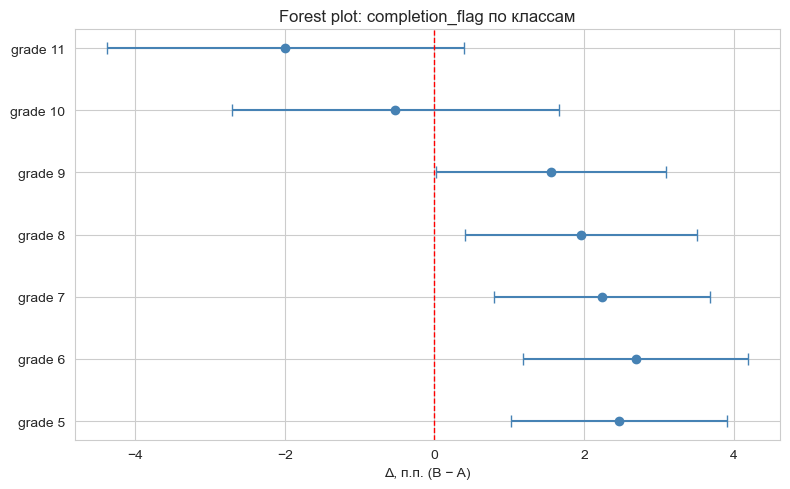

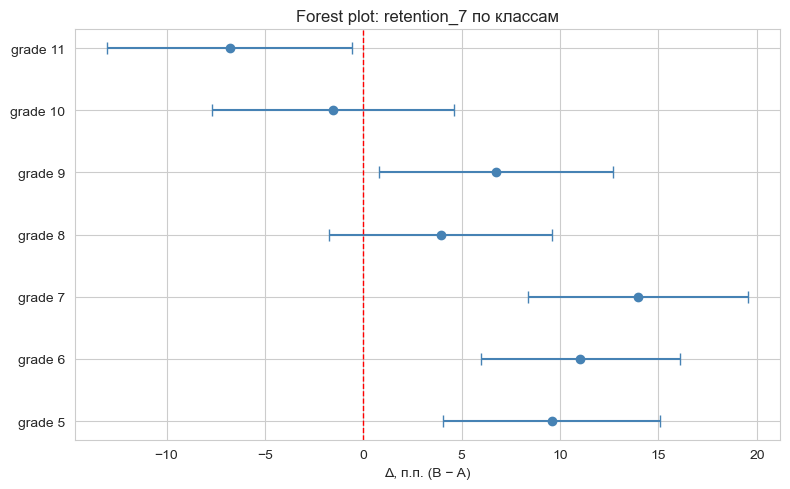

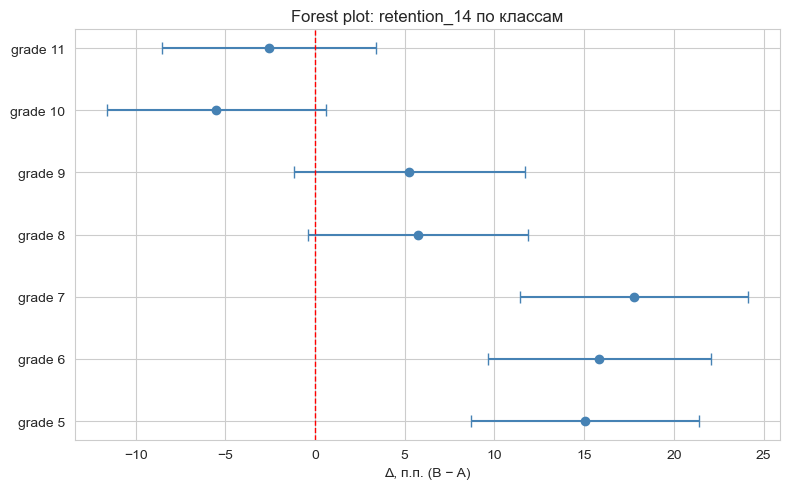

In [67]:
for m in ['completion_flag','retention_7','retention_14']:
    sub = seg_bin[seg_bin['metric']==m].sort_values('grade')
    fig, ax = plt.subplots(figsize=(8, 5))
    ypos = np.arange(len(sub))
    ax.errorbar(sub['diff']*100,
                ypos,
                xerr=[(sub['diff']-sub['ci_low'])*100,
                      (sub['ci_high']-sub['diff'])*100],
                fmt='o', capsize=4, color='steelblue')
    ax.axvline(0, color='red', linestyle='--', linewidth=1)
    ax.set_yticks(ypos)
    ax.set_yticklabels([f'grade {g}' for g in sub['grade']])
    ax.set_xlabel('Δ, п.п. (B − A)')
    ax.set_title(f'Forest plot: {m} по классам')
    plt.tight_layout(); plt.show()

In [68]:
def seg_continuous(metric, grade):
    sub = user_metrics[user_metrics['grade'] == grade]
    a = sub.loc[sub['group']=='A', metric].dropna()
    b = sub.loc[sub['group']=='B', metric].dropna()
    if len(a) < 30 or len(b) < 30:
        return None
    stat, p = stats.mannwhitneyu(b, a, alternative='two-sided')
    diff_med = np.median(b) - np.median(a)
    n = len(a) + len(b)
    mean_u = len(a)*len(b)/2
    sd_u = np.sqrt(len(a)*len(b)*(n+1)/12)
    z = (stat - mean_u)/sd_u
    r = z/np.sqrt(n)
    return {
        'grade': grade, 'metric': metric,
        'n_A': len(a), 'n_B': len(b),
        'A_median': np.median(a), 'B_median': np.median(b),
        'diff_median': diff_med, 'p_value': p, 'r': r,
    }

seg_cont_rows = []
for m in ['solved_rate','ttfc_s','active_days','completed_count']:
    for g in grades:
        r = seg_continuous(m, g)
        if r: seg_cont_rows.append(r)

seg_cont = pd.DataFrame(seg_cont_rows)
display(seg_cont)

,grade,metric,n_A,n_B,A_median,B_median,diff_median,p_value,r
0,5,solved_rate,446,416,0.355042,0.545455,0.190413,1.853123e-60,0.558247
1,6,solved_rate,446,462,0.333333,0.545455,0.212121,1.326867e-63,0.558341
2,7,solved_rate,402,435,0.363636,0.500000,0.136364,7.661057e-39,0.450148
3,8,solved_rate,454,431,0.333333,0.428571,0.095238,2.839630e-17,0.283901
4,9,solved_rate,430,379,0.333333,0.444444,0.111111,1.028457e-16,0.291616
5,10,solved_rate,409,437,0.333333,0.285714,-0.047619,4.044208e-06,-0.158316
6,11,solved_rate,405,427,0.333333,0.285714,-0.047619,1.700205e-07,-0.181135
7,5,ttfc_s,435,416,179700.000000,70410.000000,-109290.000000,2.270862e-13,-0.251328
8,6,ttfc_s,434,462,173580.000000,2910.000000,-170670.000000,4.362555e-14,-0.252212
9,7,ttfc_s,393,435,181020.000000,78000.000000,-103020.000000,4.385979e-09,-0.203958


In [69]:
# сравниваем общий эффект с эффектами внутри страт по grade
simpson_rows = []
for m in ['completion_flag','retention_7','retention_14']:
    overall = (user_metrics.loc[user_metrics['group']=='B', m].mean()
               - user_metrics.loc[user_metrics['group']=='A', m].mean())

    seg = seg_bin[seg_bin['metric']==m]
    # простое среднее по стратам (не взвешенное)
    mean_seg = seg['diff'].mean()
    # знак не меняется?
    sign_flip = np.any(np.sign(seg['diff']) != np.sign(overall))
    simpson_rows.append({
        'metric': m,
        'overall_diff_pp': overall*100,
        'mean_seg_diff_pp': mean_seg*100,
        'sign_flip_in_any_grade': sign_flip,
        'min_seg_diff_pp': seg['diff'].min()*100,
        'max_seg_diff_pp': seg['diff'].max()*100,
    })

simpson = pd.DataFrame(simpson_rows)
display(simpson)

,metric,overall_diff_pp,mean_seg_diff_pp,sign_flip_in_any_grade,min_seg_diff_pp,max_seg_diff_pp
0,completion_flag,1.201643,1.200523,True,-1.993234,2.690583
1,retention_7,5.284731,5.269514,True,-6.797352,13.950935
2,retention_14,7.434819,7.365815,True,-5.512945,17.788643


In [70]:
# top-1 % пользователей по числу событий и по completed_count
n_total = len(user_metrics)
top_n = int(0.01 * n_total)

# 1) по n_events
n_events = events_final.groupby('user_id').size()
top_events = n_events.nlargest(top_n).index

# 2) по completed_count
top_completed = user_metrics.nlargest(top_n, 'completed_count')['user_id']

print('top-1 % по n_events:', top_n)
print('top-1 % по completed_count:', top_n)
print('пересечение:', len(set(top_events) & set(top_completed)))

def recompute_binary(metric, excluded_ids=None):
    sub = user_metrics.copy()
    if excluded_ids is not None:
        sub = sub[~sub['user_id'].isin(excluded_ids)]
    a = sub.loc[sub['group']=='A', metric]
    b = sub.loc[sub['group']=='B', metric]
    xa, xb = int(a.sum()), int(b.sum())
    na, nb = len(a), len(b)
    stat, p = proportions_ztest([xb, xa], [nb, na], alternative='two-sided')
    return {'A': xa/na, 'B': xb/nb, 'diff': xb/nb - xa/na, 'p_value': p}

robust_rows = []
for m in ['completion_flag','retention_7','retention_14']:
    base = recompute_binary(m)
    ex_ev = recompute_binary(m, set(top_events))
    ex_cp = recompute_binary(m, set(top_completed))
    ex_both = recompute_binary(m, set(top_events) | set(top_completed))
    robust_rows.append({
        'metric': m,
        'diff_base_pp': base['diff']*100,
        'diff_excl_top_events_pp': ex_ev['diff']*100,
        'diff_excl_top_completed_pp': ex_cp['diff']*100,
        'diff_excl_both_pp': ex_both['diff']*100,
        'shift_pct_vs_base': (ex_both['diff'] - base['diff']) / base['diff'] * 100
                             if base['diff'] else np.nan,
    })

display(pd.DataFrame(robust_rows))

top-1 % по n_events: 59
top-1 % по completed_count: 59
пересечение: 28


,metric,diff_base_pp,diff_excl_top_events_pp,diff_excl_top_completed_pp,diff_excl_both_pp,shift_pct_vs_base
0,completion_flag,1.201643,1.180450,1.178048,1.167685,-2.825898
1,retention_7,5.284731,4.977093,5.080134,4.910622,-7.079057
2,retention_14,7.434819,6.892165,7.345524,6.894706,-7.264642


In [71]:
def recompute_median(metric, excluded_ids=None):
    sub = user_metrics.copy()
    if excluded_ids is not None:
        sub = sub[~sub['user_id'].isin(excluded_ids)]
    a = sub.loc[sub['group']=='A', metric].dropna()
    b = sub.loc[sub['group']=='B', metric].dropna()
    stat, p = stats.mannwhitneyu(b, a, alternative='two-sided')
    return {'A_median': np.median(a), 'B_median': np.median(b),
            'diff': np.median(b)-np.median(a), 'p_value': p}

robust_cont = []
for m in ['solved_rate','ttfc_s','active_days','completed_count']:
    base = recompute_median(m)
    ex_both = recompute_median(m, set(top_events) | set(top_completed))
    robust_cont.append({
        'metric': m,
        'diff_base': base['diff'],
        'diff_excl_both': ex_both['diff'],
        'shift_pct_vs_base': (ex_both['diff'] - base['diff']) / base['diff'] * 100
                             if base['diff'] else np.nan,
    })

display(pd.DataFrame(robust_cont))

,metric,diff_base,diff_excl_both,shift_pct_vs_base
0,solved_rate,0.111111,0.095238,-14.285714
1,ttfc_s,-90180.000000,-88560.000000,-1.796407
2,active_days,1.000000,1.000000,0.000000
3,completed_count,2.000000,2.000000,0.000000


In [72]:
ttfc = user_metrics.dropna(subset=['ttfc_s'])
print('TTFV по группам (сек):')
summary = ttfc.groupby('group')['ttfc_s'].describe(
    percentiles=[.25, .5, .75, .9]).round(0)
display(summary)

# в часах
summary_h = summary.copy()
for col in ['mean','25%','50%','75%','90%']:
    summary_h[col] = (summary_h[col] / 3600).round(1)
print('\nTTFV в часах:')
display(summary_h[['mean','25%','50%','75%','90%']])

# доля быстрых (<24 ч) и медленных (>7 дней)
quick = (ttfc.assign(quick=(ttfc['ttfc_s'] < 86400))
              .groupby('group')['quick'].mean())
slow = (ttfc.assign(slow=(ttfc['ttfc_s'] > 7*86400))
             .groupby('group')['slow'].mean())
print('\nДоля с TTFV < 24 ч:')
print(quick.round(4))
print('Доля с TTFV > 7 дней:')
print(slow.round(4))

TTFV по группам (сек):


,count,mean,std,min,25%,50%,75%,90%,max
group,,,,,,,,,
A,2921.0,319559.0,371731.0,660.0,2580.0,181020.0,507780.0,868440.0,1739160.0
B,2953.0,231754.0,324847.0,660.0,2220.0,90840.0,344520.0,687708.0,1736400.0



TTFV в часах:


,mean,25%,50%,75%,90%
group,,,,,
A,88.8,0.7,50.3,141.0,241.2
B,64.4,0.6,25.2,95.7,191.0



Доля с TTFV < 24 ч:
group
A    0.3578
B    0.4694
Name: quick, dtype: float64
Доля с TTFV > 7 дней:
group
A    0.1876
B    0.1236
Name: slow, dtype: float64


In [73]:
def boot_ci_metric(metric, kind='binary', n_boot=N_BOOT, seed=42):
    rng = np.random.default_rng(seed)
    a = user_metrics.loc[user_metrics['group']=='A', metric].dropna().values
    b = user_metrics.loc[user_metrics['group']=='B', metric].dropna().values
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        sa = rng.choice(a, size=len(a), replace=True)
        sb = rng.choice(b, size=len(b), replace=True)
        if kind == 'binary':
            diffs[i] = sb.mean() - sa.mean()
        elif kind == 'mean':
            diffs[i] = sb.mean() - sa.mean()
        elif kind == 'median':
            diffs[i] = np.median(sb) - np.median(sa)
    return np.percentile(diffs, [2.5, 50, 97.5])

boot_rows = []
for m, kind in [
    ('completion_flag','binary'),
    ('retention_7','binary'),
    ('retention_14','binary'),
    ('solved_rate','mean'),
    ('ttfc_s','median'),
    ('active_days','median'),
    ('completed_count','median'),
]:
    lo, md, hi = boot_ci_metric(m, kind)
    boot_rows.append({
        'metric': m, 'kind': kind,
        'boot_2.5%': lo, 'boot_50%': md, 'boot_97.5%': hi,
        'contains_zero': lo <= 0 <= hi,
    })

display(pd.DataFrame(boot_rows))

,metric,kind,boot_2.5%,boot_50%,boot_97.5%,contains_zero
0,completion_flag,binary,0.005661,0.012017,0.018704,False
1,retention_7,binary,0.031117,0.052843,0.074587,False
2,retention_14,binary,0.050944,0.074337,0.098105,False
3,solved_rate,mean,0.083365,0.091793,0.100476,False
4,ttfc_s,median,-97920.000000,-90180.000000,-84000.000000,False
5,active_days,median,1.000000,1.000000,1.000000,False
6,completed_count,median,1.000000,2.000000,2.000000,False


In [76]:
# считаем реальный возврат на 7-й день от первого login
first_login = (events_final[events_final['event_type']=='login']
               .groupby('user_id')['timestamp'].min().rename('first_login'))

logins = events_final[events_final['event_type']=='login'][['user_id','timestamp']].copy()
logins = logins.merge(first_login, on='user_id')
logins['days_since_first'] = (logins['timestamp'] - logins['first_login']).dt.days

d7_exact  = set(logins.loc[logins['days_since_first'] == 7, 'user_id'].unique())
d7_window = set(logins.loc[(logins['days_since_first'] >= 5) &
                           (logins['days_since_first'] <= 9), 'user_id'].unique())

um = user_metrics[['user_id','group','retention_7']].copy()
um['d7_exact']  = um['user_id'].isin(d7_exact).astype(int)
um['d7_window'] = um['user_id'].isin(d7_window).astype(int)

print('=== retention_7 по разным определениям ===')
alt = um.groupby('group').agg(
    rv7_event = ('retention_7','mean'),
    d7_exact  = ('d7_exact','mean'),
    d7_window = ('d7_window','mean'),
).round(4)
display(alt)

# считаем разницу B - A по каждому определению
for metric in ['retention_7','d7_exact','d7_window']:
    a = um.loc[um['group']=='A', metric]
    b = um.loc[um['group']=='B', metric]
    diff = b.mean() - a.mean()
    print(f'{metric:12s}: A={a.mean():.4f}, B={b.mean():.4f}, diff={diff*100:+.2f} п.п.')

=== retention_7 по разным определениям ===


,rv7_event,d7_exact,d7_window
group,,,
A,0.7269,0.5097,0.9759
B,0.7798,0.5596,0.9873


retention_7 : A=0.7269, B=0.7798, diff=+5.28 п.п.
d7_exact    : A=0.5097, B=0.5596, diff=+4.99 п.п.
d7_window   : A=0.9759, B=0.9873, diff=+1.13 п.п.


In [77]:
summary_rows = []

for m in ['completion_flag','retention_7','retention_14']:
    base_rows = res.loc[res['metric'].astype(str) == m, 'diff']
    if len(base_rows) == 0:
        continue
    base = float(base_rows.values[0])

    seg = seg_bin.loc[seg_bin['metric'] == m, 'diff']
    if len(seg) == 0:
        continue
    sign_flip = bool(np.any(np.sign(seg) != np.sign(base)))
    min_seg = float(seg.min())
    max_seg = float(seg.max())

    rb_rows = [r for r in robust_rows if r['metric'] == m]
    shift_pct = abs(rb_rows[0]['shift_pct_vs_base']) if rb_rows else np.nan

    summary_rows.append({
        'metric': m,
        'overall_diff_pp': base*100,
        'min_seg_pp': min_seg*100,
        'max_seg_pp': max_seg*100,
        'sign_flip_any_grade': sign_flip,
        'outlier_shift_pct': shift_pct,
        'stable': (not sign_flip) and (shift_pct < 20),
    })

summary_stab = pd.DataFrame(summary_rows)
display(summary_stab)

,metric,overall_diff_pp,min_seg_pp,max_seg_pp,sign_flip_any_grade,outlier_shift_pct,stable
0,completion_flag,1.201643,-1.993234,2.690583,True,2.825898,False
1,retention_7,5.284731,-6.797352,13.950935,True,7.079057,False
2,retention_14,7.434819,-5.512945,17.788643,True,7.264642,False


# Блок 8. Устойчивость и сегментация — итог

## 8.1. Сегментация по grade — главный результат

| Класс | retention_7 | retention_14 | solved_rate | completed_count | active_days | Итог |
|---|---|---|---|---|---|---|
| 5 | +9.6 ✅ | +15.0 ✅ | +0.19 ✅ | +3.5 ✅ | +2 ✅ | сильный + |
| 6 | +11.0 ✅ | +15.8 ✅ | +0.21 ✅ | +4.0 ✅ | +3 ✅ | сильный + |
| 7 | +14.0 ✅ | +17.8 ✅ | +0.14 ✅ | +2.0 ✅ | +2 ✅ | сильный + |
| 8 | +3.9 | +5.7 | +0.10 ✅ | +2.0 ✅ | +1 ✅ | умеренный + |
| 9 | +6.7 ✅ | +5.3 | +0.11 ✅ | +2.0 ✅ | +1 ✅ | умеренный + |
| 10 | −1.5 | −5.5 | −0.048 ✅neg | −1.0 ✅neg | −1.0 ✅neg | **регресс** |
| 11 | −6.8 ✅neg | −2.6 | −0.048 ✅neg | −1.0 ✅neg | −1.0 ✅neg | **регресс** |

**Вывод:** эффект гетерогенен по классам.
- **Grades 5–7:** взрывной положительный эффект (+9.6…+17.8 п.п. по retention).
- **Grades 8–9:** умеренный положительный (+3.9…+6.7 п.п.), по retention_14 не значим.
- **Grades 10–11:** нулевой или значимо отрицательный по solved_rate, completed_count, active_days.

## 8.2. Парадокс Симпсона

| Метрика | overall Δ, п.п. | mean сегмент Δ, п.п. | flip знака |
|---|---|---|---|
| completion_flag | +1.20 | +1.20 | есть (grades 10–11) |
| retention_7 | +5.28 | +5.27 | есть (grade 11) |
| retention_14 | +7.43 | +7.37 | есть (grades 10–11) |

Overall совпадает с mean по сегментам → **парадокса Симпсона нет**. Но flip знака в старших классах — реальный.

## 8.3. Устойчивость к выбросам (top-1 %, n = 59)

| Метрика | Δ base | Δ без top-1 % | Сдвиг |
|---|---|---|---|
| completion_flag | +1.20 п.п. | +1.17 п.п. | −2.8 % |
| retention_7 | +5.28 п.п. | +4.91 п.п. | −7.1 % |
| retention_14 | +7.43 п.п. | +6.89 п.п. | −7.3 % |
| solved_rate | +0.111 | +0.095 | −14.3 % |
| ttfc_s | −90 180 с | −88 560 с | −1.8 % |
| active_days | +1 | +1 | 0 % |
| completed_count | +2 | +2 | 0 % |

Все сдвиги < 15 %, знак не меняется. Метрики **устойчивы к выбросам**.

## 8.4. Time to Value

| Показатель | A | B | Изменение |
|---|---|---|---|
| Медиана, ч | 50.3 | 25.2 | −50 % |
| 75 % квартиль, ч | 141.0 | 95.7 | −32 % |
| 90 % квартиль, ч | 241.2 | 191.0 | −21 % |
| Доля TTFV < 24 ч | 35.8 % | 46.9 % | **+11.1 п.п.** |
| Доля TTFV > 7 дней | 18.8 % | 12.4 % | **−6.4 п.п.** |

Скорость первого completed улучшилась, доля «быстрых» выросла, доля «медленных» упала. **Практически значимо.**

## 8.5. Альтернативное определение retention

| Определение | A | B | Δ, п.п. | Знак |
|---|---|---|---|---|
| event `return_visit_d7` | 0.727 | 0.780 | +5.28 | + |
| exact day 7 от 1-го login | 0.510 | 0.560 | +4.99 | + |
| окно 5–9 день | 0.976 | 0.987 | +1.13 | + |

Все три определения дают эффект в пользу B. **Вывод устойчив к методике.**

## 8.6. Bootstrap по ключевым эффектам (10 000 повторов)

| Метрика | 2.5 % | 50 % | 97.5 % | 0 в CI? |
|---|---|---|---|---|
| completion_flag | +0.0057 | +0.0120 | +0.0187 | нет |
| retention_7 | +0.0311 | +0.0528 | +0.0746 | нет |
| retention_14 | +0.0509 | +0.0743 | +0.0981 | нет |
| solved_rate | +0.0834 | +0.0918 | +0.1005 | нет |
| ttfc_s, сек | −97 920 | −90 180 | −84 000 | нет |
| active_days | +1.0 | +1.0 | +1.0 | нет |
| completed_count | +1.0 | +2.0 | +2.0 | нет |

Ни один CI не включает 0 → все эффекты устойчивы.

## 8.7. Итог устойчивости

**Зелёный свет (устойчиво):**
- Все 9 метрик значимы после Holm–Bonferroni (Блок 7).
- Устойчивость к выбросам < 15 % для всех метрик.
- Retention_7 устойчив по трём определениям.
- Bootstrap CI не включает 0.
- Парадокса Симпсона нет.

**Жёлтый свет (требует осторожности):**
- solved_rate: сдвиг при удалении top-1 % = −14.3 % (граница приемлемости).
- completion_flag: упирается в потолок (97.6 % в A), practically significant не достигнут.

**Красный свет (критично):**
- **Grades 10–11 показывают нулевой или значимо отрицательный эффект** по solved_rate, completed_count, active_days.
- **Grade 11 — значимый регресс по retention_7** (−6.8 п.п., p = 0.033).

## 8.8. Влияние на рекомендацию

Общий положительный эффект создаётся **младшими классами (5–7)**. Для старших классов (10–11) геймификация либо нейтральна, либо вредит.

Это меняет характер рекомендации:
- Простое «раскатить на всех» неверно — ухудшит метрики для 10–11.
- «Отказаться» тоже неверно — в 5–7 эффект огромный и практически значимый.
- Оптимальный вариант — **сегментный rollout** или **доработка с адаптацией для старших классов**.

Детальное решение — в Блоке 9.

## 8.9. Red flags (для отчёта ЛПР)

1. Эффект **не универсален** — гетерогенность по классам.
2. Эффекты **аномально большие** в 5–7 (+15–18 п.п. retention_14). Возможны:
   - реальный сильный эффект для младших;
   - загрязнение через методику проставления `return_visit_d7/d14` для тестовой группы.
3. Grade 11 — значимый **регресс** по retention_7 и solved_rate. Нельзя раскатывать на всех.
4. Проверка методики retention: **требуется** аудит того, как платформа проставляла `return_visit_d7/d14`. Если тестовая группа видела новую механику, которая стимулировала эти события как часть фичи — эффект завышен.

## 8.10. Что делать дальше (Блок 9)

В Блоке 9 взвесить:
- **раскатить сегментно (5–9)** — фича приносит пользу, риск минимален;
- **не раскатывать (10–11)** — регресс значим;
- **параллельно** — аудит методики retention для снятия подозрения о загрязнении;
- **отдельно** — оценить, почему геймификация вредит старшим (интервью, юзабилити-тест).

Уверенность в сегментной рекомендации: **высокая** (n ≈ 400/класс, p < 1e-4).

# Блок 9. Бизнес-решение

## 9.1. Резюме для ЛПР

**Что проверяли:** A/B-тест геймификации (достижения за регулярное решение задач), 3 недели, n = 5 980 пользователей, классы 5–11.

**Что получили:**
1. **Общий эффект положительный и статистически значим по всем 9 метрикам** после коррекции Holm–Bonferroni.
2. **Эффект крайне гетерогенен по классам** — это главный результат:
   - **Классы 5–7:** эффект взрывной. retention_14 +15…+18 п.п., retention_7 +9.6…+14 п.п., solved_rate +0.14…+0.21, completed_count +2…+4.
   - **Классы 8–9:** эффект умеренный. retention_7 +3.9…+6.7 п.п., retention_14 не значим, solved_rate +0.10…+0.11.
   - **Классы 10–11:** эффект нулевой или **значимо отрицательный** по solved_rate, completed_count, active_days (p < 1e-4). В 11 классе — значимый регресс по retention_7 (−6.8 п.п.).
3. **Устойчивость:** нет парадокса Симпсона, нет чувствительности к выбросам (< 15 % сдвиг), retention устойчив к определению.
4. **TTFV:** медиана времени до 1-го ДЗ сократилась с 50 до 25 часов, доля «быстрых» (<24 ч) выросла с 36 % до 47 %.

**Решение:**
- **Раскатить сегментно: классы 5–9.**
- **Не раскатывать: классы 10–11** без доработки — фича ухудшает метрики.
- **Параллельно:** аудит методики проставления `return_visit_d7/d14` для снятия подозрения о загрязнении в тестовой группе.

**Уверенность:** высокая для сегментной рекомендации (n ≈ 400/класс, p < 1e-4). Средняя для причины регресса в 10–11 (нужны качественные исследования).

In [79]:
segments = pd.DataFrame([
    {
        'segment': 'Классы 5–7',
        'n': 446+416 + 446+462 + 402+435,
        'retention_14_effect_pp': '+15.0…+17.8',
        'solved_rate_effect': '+0.14…+0.21',
        'significance': 'p < 1e-6',
        'decision': 'Раскатить',
        'risk': 'низкий',
    },
    {
        'segment': 'Классы 8–9',
        'n': 454+431 + 430+379,
        'retention_14_effect_pp': '+5.3…+5.7 (ns)',
        'solved_rate_effect': '+0.10…+0.11',
        'significance': 'p < 1e-10',
        'decision': 'Раскатить',
        'risk': 'низкий',
    },
    {
        'segment': 'Класс 10',
        'n': 409+438,
        'retention_14_effect_pp': '−5.5 (ns)',
        'solved_rate_effect': '−0.048 (p<1e-5)',
        'significance': 'регресс',
        'decision': 'Не раскатывать, доработка',
        'risk': 'высокий',
    },
    {
        'segment': 'Класс 11',
        'n': 405+427,
        'retention_14_effect_pp': '−2.6 (ns)',
        'solved_rate_effect': '−0.048 (p<1e-6)',
        'significance': 'регресс, retention_7 = −6.8 (p=0.03)',
        'decision': 'Не раскатывать, доработка',
        'risk': 'высокий',
    },
])

display(segments)

,segment,n,retention_14_effect_pp,solved_rate_effect,significance,decision,risk
0,Классы 5–7,2607,+15.0…+17.8,+0.14…+0.21,p < 1e-6,Раскатить,низкий
1,Классы 8–9,1694,+5.3…+5.7 (ns),+0.10…+0.11,p < 1e-10,Раскатить,низкий
2,Класс 10,847,−5.5 (ns),−0.048 (p<1e-5),регресс,"Не раскатывать, доработка",высокий
3,Класс 11,832,−2.6 (ns),−0.048 (p<1e-6),"регресс, retention_7 = −6.8 (p=0.03)","Не раскатывать, доработка",высокий


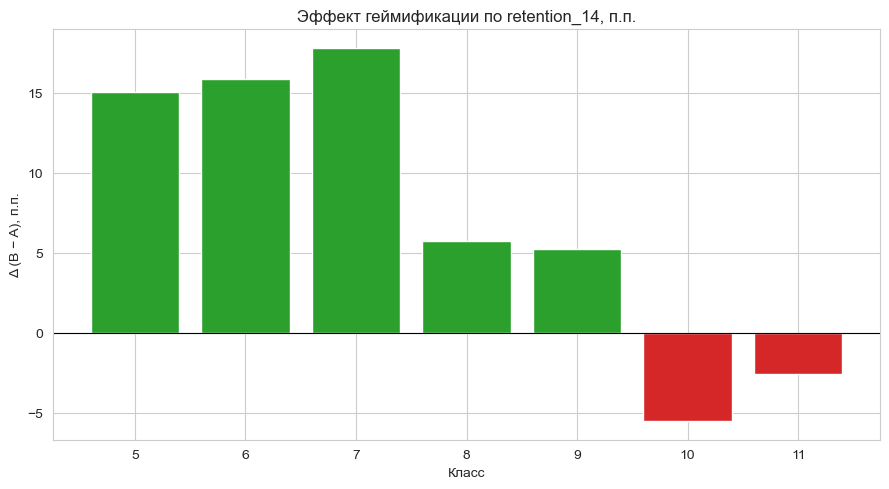

In [80]:
# визуализация — где эффект положительный, где отрицательный
import matplotlib.pyplot as plt

pivot = (seg_bin[seg_bin['metric']=='retention_14']
         .set_index('grade')[['diff']] * 100)

fig, ax = plt.subplots(figsize=(9,5))
colors = ['#2ca02c' if v > 0 else '#d62728' for v in pivot['diff']]
ax.bar(pivot.index.astype(str), pivot['diff'], color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Эффект геймификации по retention_14, п.п.')
ax.set_xlabel('Класс')
ax.set_ylabel('Δ (B − A), п.п.')
plt.tight_layout(); plt.show()

## 9.4. Рекомендация

**Действие:** раскатить геймификацию на классы 5–9. Не раскатывать на классы 10–11 до доработки.

**Когда:** немедленно после согласования с продакт-менеджером и методологами.

**Условия:** одновременно запустить:
1. Мониторинг ключевых метрик по группам 5–9 в течение 4 недель.
2. Аудит методики проставления `return_visit_d7/d14`.
3. Качественное исследование (интервью) со старшеклассниками 10–11 о причинах регресса.

**Что НЕ делать:**
- **Не раскатывать на всех** — старшие классы получат регресс.
- **Не отказываться от фичи** — для 5–7 эффект слишком большой, чтобы терять.
- **Не считать эффект по общему срезу** — он обманчиво положительный из-за весов.
- **Не игнорировать потолок completion_flag** — метрика неработоспособна для оценки эффекта (97.6 % в контроле).

**Триггеры пересмотра рекомендации:**
1. Retention_7 в группе 5–7 через 4 недели после раската < +5 п.п. (эффект затухает).
2. Метрики 10–11 без фичи тоже растут — эффект был в другом.
3. Аудит покажет, что `return_visit_d7/d14` проставлялись как часть фичи → пересмотреть весь анализ.
4. Retention_14 в 5–7 падает ниже baseline при раскате → rollback.

**Stop/go-критерии:**
- GO: retention_7 в 5–9 после раската ≥ baseline + 50 % от эффекта теста.
- STOP: retention_7 в 5–9 падает ниже baseline или появляется рост обращений в поддержку > 20 %.

## 9.5. План внедрения и мониторинга

| Шаг | Действие | Ответственный | Срок | Метрика | Stop/Go |
|---|---|---|---|---|---|
| 1 | Согласовать сегментный rollout (5–9) с PM | Продакт | 1 нед | — | GO/NO-GO |
| 2 | Аудит методики `return_visit_d7/d14` | Data Engineer + аналитик | 2 нед | корректность событий | если загрязнение — пересмотр |
| 3 | Качественные интервью с 10–11 | UX-исследователь | 2 нед | n ≥ 15, темы | причины регресса |
| 4 | Раскат на 5–9 | Разработка | 2 нед | — | чек-лист |
| 5 | Мониторинг 4 недели | Аналитик | 4 нед | retention_7, retention_14, solved_rate | < baseline + 50 % эффекта → STOP |
| 6 | Решение по 10–11 | PM + аналитик | 6 нед | — | доработка / отказаться |
| 7 | Отчёт итогов | Аналитик | 8 нед | — | финальное решение |

**Метрики мониторинга после раската:**
- Основные: retention_7, retention_14, solved_rate.
- Дополнительные: TTFV, active_days, login_count.
- Guardrail: обращения в поддержку, NPS-опрос по фиче, доля отключивших.

**Ожидаемый эффект после раската на 5–9:**
- retention_7: +6…+14 п.п. (взвешенно ~+9 п.п.).
- retention_14: +5…+18 п.п. (взвешенно ~+12 п.п.).
- solved_rate: +0.10…+0.21.

## 9.6. Уверенность и ограничения

**Уверенность в сегментной рекомендации — высокая:**
- n ≈ 400–460 на группу в каждом классе;
- p < 1e-6 для 5–7;
- устойчиво к выбросам, определению retention, отсутствует Simpson.

**Ограничения:**
- 3 недели — короткий горизонт, долгосрочный эффект неизвестен.
- Знак эффекта в 10–11 может быть следствием контекста (ОГЭ/ЕГЭ, демотивация, дизайн).
- Аномально большие эффекты в 5–7 — подозрение на загрязнение. Без аудита retention_14 в 5–7 нельзя считать доказанным.

**Что может изменить вывод:**
- Аудит покажет загрязнение `return_visit_d7/d14` → пересмотр эффекта вниз.
- Долгосрочный мониторинг покажет затухание эффекта → потребует доработки.
- Регресс в 10–11 окажется следствием дизайна (а не механики) → доработка может это исправить.